# TP 2 - Clasificación de Texto con MLP (Perceptrón Multicapa)
### Redes Neuronales / Deep Learning

**Alumno**: Facundo Ortega

**Legajo**: 65560

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet en 20 categorías), con el mismo pipeline de preprocesamiento y TF-IDF del TP1 (regresión softmax).

## Objetivos
1. Reemplazar la regresión softmax por un **MLP** y buscar hiperparámetros con Optuna incluyendo:
   - funciones de activación,
   - cantidad de capas ocultas (1, 2 o 3),
   - neuronas por capa,
   - optimizador (Adam, RMSprop, SGD) con sus parámetros de **momento de orden 1 y 2**,
   - los hiperparámetros del TP1 (preprocesamiento, TF-IDF, learning rate, batch size).
2. Usar **pruning** de Optuna para ahorrar tiempo de búsqueda (bonus).
3. Encontrar una arquitectura que **sobreajuste** el problema.
4. Analizar y comparar performance y tiempos de **todos** los entrenamientos.

## Qué cambia respecto del TP1

| | TP1 (softmax) | TP2 (MLP) |
|---|---|---|
| Modelo | 1 capa lineal | 1–3 capas ocultas + activación no lineal + dropout |
| Optimizador | Adam fijo | Adam / RMSprop / SGD, con sus momentos |
| Objetivo de Optuna | val_acc de la **última** época (5) | **mejor** val_acc de hasta 15 épocas |
| Ahorro de tiempo | caché del preprocesamiento | caché del preprocesamiento + caché de TF-IDF + **pruning** + early stopping |
| MLflow | runs mezclados en un run implícito | **un run por trial** |
| Reproducibilidad | sampler sin semilla | `TPESampler(seed=SEED)` |

## 0. Setup

Mismos frameworks que en el TP1 (PyTorch, scikit-learn, NLTK, TensorBoard, MLflow, Optuna), más `pandas` para las tablas de análisis y `time` para medir tiempos.

In [2]:
!pip install -q mlflow optuna


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import re
import math
import time
import glob
import random
from functools import lru_cache

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

In [4]:
for recurso in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

## 1. Datos, preprocesamiento y TF-IDF

Reutilizamos el pipeline del TP1:
- carga de 20 Newsgroups sin headers, footers ni citas;
- `preprocess_text` (minúsculas, tokenización, stopwords opcionales, stem o lemmatize);
- precálculo de las 6 combinaciones de preprocesamiento.

Mejora de velocidad: `lru_cache` memoriza el stem o lema de cada palabra, así que el preprocesamiento da el mismo resultado pero es varias veces más rápido.

In [5]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"Train: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Train: 11314 documentos | Test: 7532 documentos


In [6]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

# Memorizamos stem/lemmatize por palabra: el vocabulario se repite muchísimo, así que la
# segunda vez que aparece una palabra no se recalcula. Mismo resultado que en el TP1, más rápido.
_stem = lru_cache(maxsize=None)(STEMMER.stem)
_lemmatize = lru_cache(maxsize=None)(LEMMATIZER.lemmatize)


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())             # minúsculas + tokenización
    tokens = [t for t in tokens if t.isalpha()]      # sólo tokens alfabéticos
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [_stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [_lemmatize(t) for t in tokens]
    return " ".join(tokens)


print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [7]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)   # aprende vocabulario + idf SÓLO con train
    X_test = vectorizer.transform(test_texts)         # aplica lo aprendido a test (sin data leakage)
    return X_train, X_test, vectorizer


# Split fijo train/validación (80/20 estratificado), el mismo para todos los trials -> comparables
y_train_all = np.asarray(newsgroups_train.target)
y_test = np.asarray(newsgroups_test.target)
idx_tr, idx_val = train_test_split(np.arange(len(y_train_all)), test_size=0.2,
                                   random_state=SEED, stratify=y_train_all)
y_tr, y_val = y_train_all[idx_tr], y_train_all[idx_val]

# Caché de representaciones TF-IDF: si dos trials piden la misma combinación de
# preprocesamiento + vectorización, la segunda vez no se recalcula.
_repr_cache = {}


def get_representation(remove_stopwords, normalization, ngram_range, max_features, min_df):
    """Devuelve (X_tr, X_val, segundos_de_vectorización) como matrices dispersas."""
    key = (remove_stopwords, normalization, ngram_range, max_features, min_df)
    if key not in _repr_cache:
        texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
        t0 = time.perf_counter()
        X_tr, X_val, _ = vectorize_data([texts[i] for i in idx_tr], [texts[i] for i in idx_val],
                                        ngram_range, max_features, min_df)
        _repr_cache[key] = (X_tr, X_val, time.perf_counter() - t0)
    return _repr_cache[key]


print(f"Train de búsqueda: {len(idx_tr)} docs | Validación: {len(idx_val)} docs")

Train de búsqueda: 9051 docs | Validación: 2263 docs


**Novedad: caché de representaciones TF-IDF.** En el TP1 cada trial re-vectorizaba. Ahora `get_representation` guarda las matrices TF-IDF (dispersas) por combinación de `(stopwords, normalización, n-gramas, max_features, min_df)`. Si dos trials piden la misma representación, la segunda vez es instantánea.

El split train/validación es **fijo** (80/20 estratificado, `random_state=SEED`): todos los trials se evalúan sobre los mismos 2.263 documentos de validación, así que son comparables. El **test no se usa en la búsqueda**.

## 2. Modelo: Perceptrón Multicapa (MLP)

### De la regresión softmax al MLP

La regresión softmax del TP1 calcula los logits como una función **lineal** de la entrada, $z = Wx + b$, y por eso sólo puede trazar fronteras de decisión lineales (hiperplanos). Un MLP agrega **capas ocultas**: cada una aplica una transformación lineal seguida de una **función de activación no lineal** $\phi$:

$$h^{(1)} = \phi\big(W^{(1)}x + b^{(1)}\big),\quad h^{(2)} = \phi\big(W^{(2)}h^{(1)} + b^{(2)}\big),\quad \dots,\quad z = W^{(L+1)}h^{(L)} + b^{(L+1)}$$

y la salida $z$ (logits) va a `CrossEntropyLoss` igual que antes.

**Por qué hace falta la no linealidad**: sin $\phi$, componer capas lineales da otra capa lineal, $W^{(2)}(W^{(1)}x) = (W^{(2)}W^{(1)})x$. No se gana nada. Con $\phi$, el MLP puede aprender representaciones intermedias y fronteras no lineales. Por el **teorema de aproximación universal**, con suficientes neuronas puede aproximar cualquier función continua.

**Cantidad de parámetros**: para capas de tamaños $d \to h_1 \to h_2 \to K$ es $(d+1)h_1 + (h_1+1)h_2 + (h_2+1)K$.

Con TF-IDF, $d$ es grande (hasta 10.000), así que **la primera capa concentra casi todos los parámetros**. Por ejemplo, con $d=10.000$ y $h_1=512$, la primera capa sola tiene ~5,1 M de parámetros, contra 200.020 de toda la regresión softmax del TP1.

### Funciones de activación incluidas en la búsqueda

| Activación | Fórmula | Derivada | Características |
|---|---|---|---|
| **Sigmoid** | $\sigma(u)=\frac{1}{1+e^{-u}}$ | $\sigma(1-\sigma)\le 0.25$ | Salida en (0,1), no centrada en 0. Se **satura** para $\lvert u\rvert$ grande (derivada ≈ 0) → *vanishing gradient*: con varias capas, el gradiente se multiplica por ≤0.25 en cada una |
| **Tanh** | $\tanh(u)$ | $1-\tanh^2(u)\le 1$ | Centrada en 0 (mejor que sigmoid), pero también se satura |
| **ReLU** | $\max(0,u)$ | 1 si $u>0$, 0 si no | No se satura para $u>0$, barata. Neuronas "muertas" si quedan siempre en $u<0$ |
| **Leaky ReLU** | $\max(0.01u,u)$ | 1 ó 0.01 | Como ReLU, pero con gradiente pequeño para $u<0$ (evita neuronas muertas) |
| **ELU** | $u$ si $u>0$; $e^{u}-1$ si no | 1 ó $e^{u}$ | Suave, con salidas negativas → activaciones con media cercana a 0 |
| **GELU** | $u\,\Phi(u)$ ($\Phi$: CDF normal) | suave | Versión "suave" de ReLU, usada en transformers |

**Dropout** (también en la búsqueda: 0, 0.2, 0.5): durante el entrenamiento apaga al azar una fracción $p$ de las neuronas de cada capa oculta, y escala las demás por $1/(1-p)$. Obliga a la red a no depender de neuronas puntuales y funciona como **regularización** contra el sobreajuste. En `model.eval()` se desactiva.

`MLP(input_dim, [], K)` (sin capas ocultas) es exactamente la regresión softmax del TP1. Lo usamos como **baseline** en el experimento de sobreajuste.

In [8]:
# Funciones de activación disponibles en la búsqueda
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "elu": nn.ELU,
    "gelu": nn.GELU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class MLP(nn.Module):
    """Perceptrón multicapa: [Linear -> activación -> (Dropout)] x n_capas_ocultas -> Linear.
    Con hidden_sizes=[] es exactamente la regresión softmax del TP1 (una sola capa lineal)."""

    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu", dropout=0.0):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))          # transformación lineal: z = W x + b
            layers.append(ACTIVATIONS[activation]())   # no linealidad
            if dropout > 0:
                layers.append(nn.Dropout(dropout))     # apaga neuronas al azar (sólo en train)
            prev = h
        layers.append(nn.Linear(prev, num_classes))    # capa de salida: logits (sin softmax)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Sanity checks
_m = MLP(50, [32, 16], NUM_CLASSES, activation="gelu", dropout=0.2)
assert _m(torch.randn(4, 50)).shape == (4, NUM_CLASSES)
print(_m)
print("Parámetros:", count_params(_m), "=", 50*32+32, "+", 32*16+16, "+", 16*20+20)
print("MLP sin capas ocultas = softmax:", count_params(MLP(50, [], NUM_CLASSES)), "parámetros =", 50*20+20)

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): GELU(approximate='none')
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=16, out_features=20, bias=True)
  )
)
Parámetros: 2500 = 1632 + 528 + 340
MLP sin capas ocultas = softmax: 1020 parámetros = 1020


## 3. Optimizadores y momentos de orden 1 y 2

Todos actualizan los pesos $\theta$ usando el gradiente $g_t=\nabla_\theta L$ del mini-batch $t$. Se diferencian en cuánta "memoria" del pasado usan.

**SGD** (sin momento): $\theta_{t+1}=\theta_t-\eta\,g_t$. Usa sólo el gradiente actual, que es ruidoso. El paso es proporcional a la magnitud del gradiente, y con TF-IDF los gradientes son chicos (features de ~0.01–0.2). Por eso SGD necesita learning rates mucho más grandes, y en la búsqueda le damos un rango propio ($10^{-2}$ a $1$).

**SGD con momento (momento de orden 1)**:
$$v_{t+1}=\mu\,v_t+g_t,\qquad \theta_{t+1}=\theta_t-\eta\,v_{t+1}$$
- $v$ es un promedio exponencial de los gradientes pasados: la **media móvil del gradiente**, que es el *momento de orden 1*.
- Acelera en direcciones consistentes (el paso efectivo es ≈ $\eta/(1-\mu)$, o sea ×10 con $\mu=0.9$ y ×100 con $\mu=0.99$) y amortigua oscilaciones.
- **Nesterov** evalúa el gradiente "un paso adelante", en la posición a la que llevaría el momento, y corrige antes.

**RMSprop (momento de orden 2)**:
$$s_{t+1}=\alpha\,s_t+(1-\alpha)\,g_t^2,\qquad \theta_{t+1}=\theta_t-\eta\,\frac{g_t}{\sqrt{s_{t+1}}+\epsilon}$$
- $s$ es la **media móvil del gradiente al cuadrado**: el *momento de orden 2* (no centrado).
- Cada parámetro se divide por la raíz de su $s$, así que **el paso queda normalizado por la escala típica de su gradiente**. Los parámetros con gradientes chicos o poco frecuentes (como los pesos de palabras raras en TF-IDF) reciben pasos relativamente más grandes.
- $\alpha$ controla cuánta memoria tiene (0.9 = memoria corta, 0.999 = larga).
- El `momentum` de RMSprop agrega además un momento de orden 1 sobre el paso normalizado.

**Adam (momentos de orden 1 y 2, con corrección de sesgo)**:
$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\quad \hat v_t=\frac{v_t}{1-\beta_2^t},\qquad \theta_{t+1}=\theta_t-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$
- $\beta_1$ es el momento de orden 1 (como el momentum), y $\beta_2$ el de orden 2 (como RMSprop).
- Como $m$ y $v$ arrancan en 0, al principio están sesgados hacia 0. Dividir por $1-\beta^t$ corrige ese sesgo.
- El paso por parámetro queda del orden de $\eta$ **sin importar la escala del gradiente**, y por eso Adam suele funcionar con lr "normales" ($10^{-3}$).

| Optimizador | Orden 1 (dirección) | Orden 2 (escala por parámetro) | Parámetros buscados |
|---|---|---|---|
| SGD | opcional (`momentum`, Nesterov) | no | lr, momentum ∈ {0, 0.5, 0.9, 0.99}, nesterov |
| RMSprop | opcional (`momentum`) | sí ($\alpha$) | lr, α ∈ {0.9, 0.99, 0.999}, momentum ∈ {0, 0.5, 0.9} |
| Adam | sí ($\beta_1$) | sí ($\beta_2$) | lr, β₁ ∈ {0.8, 0.9, 0.95}, β₂ ∈ {0.99, 0.999, 0.9999} |

In [9]:
def make_optimizer(name, params, lr, beta1=0.9, beta2=0.999, alpha=0.99, momentum=0.0, nesterov=False):
    """Crea el optimizador con sus hiperparámetros.
    - Adam:    betas=(beta1, beta2) -> beta1 = momento de orden 1, beta2 = momento de orden 2
    - RMSprop: alpha = decaimiento del momento de orden 2, momentum = momento de orden 1
    - SGD:     momentum = momento de orden 1 (no tiene momento de orden 2), nesterov opcional"""
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(beta1, beta2))
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=alpha, momentum=momentum)
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=momentum, nesterov=bool(nesterov and momentum > 0))
    raise ValueError(f"Optimizador desconocido: {name}")

## 4. Entrenamiento

`train_model` es la función del TP1 con cuatro agregados:

1. **Tiempo por época** (`epoch_time`), para comparar costos.
2. **Pruning**: si recibe un `trial`, después de cada época llama a `trial.report(val_acc, epoch)` y a `trial.should_prune()`. Si el pruner decide que el trial no promete, corta.
3. **Early stopping** (`patience`): si la val_acc no mejora en `patience` épocas seguidas, corta. Así no se gastan épocas en un modelo que ya convergió o ya empezó a sobreajustar.
4. **Divergencia**: si la loss se vuelve NaN o infinita (típico de SGD con lr y momentum altos), corta.

Además, sólo loguea en MLflow si hay un run abierto (`mlflow.active_run()`). Eso evita el run "implícito" que en el TP1 mezclaba todos los trials y causaba el error *"Run already active"*.

`to_tensor_dataset` convierte a float32 **antes** de densificar, y así evita una copia intermedia en float64 que ocupaba el doble de memoria.

`graficar_tensorboard` lee los logs de TensorBoard y los grafica con matplotlib, para que las curvas queden como imagen en el notebook y se vean en GitHub.

In [10]:
def to_tensor_dataset(X, y):
    # astype(float32) ANTES de toarray: evita crear una matriz densa float64 (el doble de memoria)
    X_dense = torch.from_numpy(X.astype(np.float32).toarray())
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()   # en GPU las operaciones son asíncronas: sincronizar antes de medir tiempo


def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="mlp",
                trial=None, patience=None, verbose=True):
    """Entrena y evalúa por época. Novedades respecto del TP1:
    - mide el tiempo de cada época;
    - trial: si se pasa un trial de Optuna, reporta la val_acc de cada época y corta si el pruner lo indica;
    - patience: early stopping si la val_acc no mejora en `patience` épocas seguidas;
    - corta si la loss diverge (NaN/inf, típico de SGD con lr muy alto);
    - sólo loguea en MLflow si hay un run abierto (evita el run 'implícito' del TP1)."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": [],
               "pruned": False, "stop_reason": "max_epochs"}
    best_acc, epochs_sin_mejora = -1.0, 0

    for epoch in range(epochs):
        _sync(); t0 = time.perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                running_loss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total
        _sync(); dt = time.perf_counter() - t0

        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"],
                        [train_loss, val_loss, train_acc, val_acc, dt]):
            history[k].append(float(v))

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f}"
                  f" - val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - {dt:.1f}s")
        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        if mlflow.active_run() is not None:
            mlflow.log_metrics({"train_loss": train_loss, "val_loss": val_loss,
                                "train_acc": train_acc, "val_acc": val_acc, "epoch_time_s": dt}, step=epoch)

        # 1) divergencia
        if not math.isfinite(train_loss):
            history["stop_reason"] = "diverged"
            break
        # 2) pruning de Optuna: reportamos la métrica intermedia y preguntamos si conviene seguir
        if trial is not None:
            trial.report(val_acc, step=epoch)
            if trial.should_prune():
                history["pruned"], history["stop_reason"] = True, "pruned"
                break
        # 3) early stopping
        if val_acc > best_acc:
            best_acc, epochs_sin_mejora = val_acc, 0
        else:
            epochs_sin_mejora += 1
        if patience is not None and epochs_sin_mejora >= patience:
            history["stop_reason"] = "early_stopping"
            break

    return history

In [11]:
def leer_scalars_tensorboard(log_dir):
    """Lee las métricas escalares que guardó SummaryWriter en log_dir: {curva: (épocas, valores)}."""
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    curvas = {}
    carpetas = {os.path.dirname(f) for f in glob.glob(os.path.join(log_dir, "**", "events.out.tfevents.*"), recursive=True)}
    for carpeta in sorted(carpetas):
        acc = EventAccumulator(carpeta)
        acc.Reload()
        sufijo = os.path.relpath(carpeta, log_dir)
        for tag in acc.Tags()["scalars"]:
            ev = acc.Scalars(tag)
            curvas[tag if sufijo == "." else sufijo] = (np.array([e.step for e in ev]) + 1, np.array([e.value for e in ev]))
    return curvas


def graficar_tensorboard(log_dir, titulo=""):
    """Replica el panel 'Scalars' de TensorBoard como imagen estática (se ve en GitHub)."""
    curvas = leer_scalars_tensorboard(log_dir)
    if not curvas:
        print(f"No se encontraron logs en {log_dir}")
        return
    grupos = sorted({n.split("_")[0] for n in curvas})
    fig, axes = plt.subplots(1, len(grupos), figsize=(7 * len(grupos), 4.2), squeeze=False)
    for ax, g in zip(axes[0], grupos):
        for nombre, (x, y) in sorted(curvas.items()):
            if nombre.split("_")[0] == g:
                ax.plot(x, y, "-o", ms=3, label=nombre[len(g) + 1:] or nombre)
        ax.set_title(g); ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend()
    fig.suptitle(titulo or f"TensorBoard: {log_dir}")
    plt.tight_layout(); plt.show()

## 5. Búsqueda de hiperparámetros con Optuna (con pruning)

### Espacio de búsqueda

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Preprocesamiento (TP1) | `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df` | igual que el TP1 |
| Entrenamiento (TP1) | `batch_size` | 32, 64, 128, 256 |
| | learning rate | Adam/RMSprop: $10^{-4}$–$3\cdot10^{-2}$ (log); SGD: $10^{-2}$–$1$ (log) |
| Arquitectura | `n_layers` | 1, 2, 3 |
| | `n_units_l1`, `n_units_l2`, `n_units_l3` | 64, 128, 256, 512 (cada capa por separado) |
| | `activation` | relu, leaky_relu, elu, gelu, tanh, sigmoid |
| | `dropout` | 0, 0.2, 0.5 |
| Optimizador | `optimizer` | adam, rmsprop, sgd |
| | momentos | ver tabla de la sección 3 |

**Espacio condicional**: Optuna permite que los hiperparámetros dependan de otros.
- `n_units_l2` sólo existe si `n_layers ≥ 2`.
- `adam_beta1` sólo si el optimizador es Adam.
- `sgd_nesterov` sólo si el momentum de SGD es mayor que 0.

Así no se gastan trials en combinaciones sin sentido. El learning rate tiene un nombre por optimizador (`lr_adam`, `lr_rmsprop`, `lr_sgd`) porque sus rangos razonables son distintos.

**Objetivo**: la **mejor** val_acc alcanzada en hasta 15 épocas (en el TP1 era la de la última época). Así no se penaliza a configuraciones que sobreajustan después de llegar a un buen valor, y la época donde se alcanzó (`best_epoch`) se reutiliza en el entrenamiento final.

### Bonus: pruning con `MedianPruner`

Después de cada época, el trial reporta su val_acc. El `MedianPruner` compara ese valor con la **mediana** de las val_acc que los trials anteriores tenían **en la misma época**. Si el trial actual está por debajo de la mediana, se **poda**: se corta y se pasa al siguiente.
- `n_startup_trials=8`: los primeros 8 trials nunca se podan (hace falta una referencia para calcular la mediana).
- `n_warmup_steps=2`: no se poda en las épocas 1 y 2 de cada trial, porque al principio las curvas son muy ruidosas.

**Ventaja**: los trials malos (lr inadecuado, sigmoid con muchas capas, SGD sin momento...) se descartan en 3–4 épocas en vez de 15. **Riesgo**: puede podar configuraciones que arrancan lento pero terminarían bien (por ejemplo, lr chicos). La celda de "ahorro del pruning" cuantifica cuánto tiempo se ganó.

Cada trial es un **run separado de MLflow** (experimento `mlp_20newsgroups_optuna`) con sus hiperparámetros, métricas por época y motivo de corte.

In [12]:
MAX_EPOCHS_SEARCH = 15   # máximo de épocas por trial (el pruner y el early stopping suelen cortar antes)
PATIENCE_SEARCH = 3      # early stopping: épocas sin mejorar la val_acc antes de cortar
N_TRIALS = 40            # cantidad de trials (bajalo si tarda demasiado en tu máquina)

mlflow.end_run()                                  # por si quedó algún run abierto
mlflow.set_experiment("mlp_20newsgroups_optuna")  # cada trial va a ser un run de este experimento


def objective(trial):
    # ---------- Hiperparámetros de preprocesamiento (los mismos del TP1) ----------
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])

    # ---------- Arquitectura ----------
    n_layers = trial.suggest_int("n_layers", 1, 3)                       # 1, 2 o 3 capas ocultas
    hidden = [trial.suggest_categorical(f"n_units_l{i+1}", [64, 128, 256, 512])
              for i in range(n_layers)]                                  # neuronas de CADA capa
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
    dropout = trial.suggest_categorical("dropout", [0.0, 0.2, 0.5])

    # ---------- Optimizador y sus parámetros (espacio condicional) ----------
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    opt_kw = {}
    if opt_name == "adam":
        lr = trial.suggest_float("lr_adam", 1e-4, 3e-2, log=True)
        opt_kw["beta1"] = trial.suggest_categorical("adam_beta1", [0.8, 0.9, 0.95])        # momento orden 1
        opt_kw["beta2"] = trial.suggest_categorical("adam_beta2", [0.99, 0.999, 0.9999])   # momento orden 2
    elif opt_name == "rmsprop":
        lr = trial.suggest_float("lr_rmsprop", 1e-4, 3e-2, log=True)
        opt_kw["alpha"] = trial.suggest_categorical("rmsprop_alpha", [0.9, 0.99, 0.999])   # momento orden 2
        opt_kw["momentum"] = trial.suggest_categorical("rmsprop_momentum", [0.0, 0.5, 0.9])  # momento orden 1
    else:
        lr = trial.suggest_float("lr_sgd", 1e-2, 1.0, log=True)   # SGD necesita lr mucho más grande
        opt_kw["momentum"] = trial.suggest_categorical("sgd_momentum", [0.0, 0.5, 0.9, 0.99])  # momento orden 1
        if opt_kw["momentum"] > 0:
            opt_kw["nesterov"] = trial.suggest_categorical("sgd_nesterov", [False, True])

    # ---------- Datos ----------
    X_tr, X_val, vec_time = get_representation(remove_stopwords, normalization, ngram_tuple, max_features, min_df)
    torch.manual_seed(SEED)   # misma inicialización/orden de batches para todos los trials
    train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=1024, shuffle=False)

    # ---------- Modelo + entrenamiento ----------
    model = MLP(X_tr.shape[1], hidden, NUM_CLASSES, activation=activation, dropout=dropout)
    optimizer = make_optimizer(opt_name, model.parameters(), lr, **opt_kw)
    n_params = count_params(model)

    with mlflow.start_run(run_name=f"trial_{trial.number}"):
        mlflow.log_params(trial.params)
        mlflow.log_param("n_params", n_params)
        history = train_model(model, train_loader, val_loader, optimizer, MAX_EPOCHS_SEARCH,
                              trial=trial, patience=PATIENCE_SEARCH, verbose=False)
        best_val = max(history["val_acc"])
        mlflow.log_metric("best_val_acc", best_val)
        mlflow.set_tag("stop_reason", history["stop_reason"])

    # Guardamos todo lo necesario para el análisis (también en los trials podados)
    trial.set_user_attr("history", history)
    trial.set_user_attr("n_params", n_params)
    trial.set_user_attr("hidden", hidden)
    trial.set_user_attr("lr", lr)
    trial.set_user_attr("n_features", int(X_tr.shape[1]))
    trial.set_user_attr("vectorize_time", vec_time)
    trial.set_user_attr("train_time", float(sum(history["epoch_time"])))
    trial.set_user_attr("best_epoch", int(np.argmax(history["val_acc"])) + 1)

    print(f"trial {trial.number:3d} | {history['stop_reason']:14s} | épocas={len(history['val_acc']):2d} | "
          f"best_val_acc={best_val:.4f} | {opt_name:7s} lr={lr:.2e} | {activation:10s} | capas={hidden} "
          f"drop={dropout} | {sum(history['epoch_time']):6.1f}s")

    if history["pruned"]:
        raise optuna.TrialPruned()   # le avisamos a Optuna que este trial fue podado
    return best_val                   # objetivo: la MEJOR val_acc (no la de la última época)


optuna.logging.set_verbosity(optuna.logging.WARNING)   # usamos nuestro propio print de una línea por trial
study = optuna.create_study(
    direction="maximize",
    study_name="mlp_20newsgroups",
    sampler=optuna.samplers.TPESampler(seed=SEED),                          # búsqueda reproducible
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=2),  # BONUS: pruning
)
t_search = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
t_search = time.perf_counter() - t_search

n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"\nBúsqueda terminada en {t_search/60:.1f} min | completos: {len(study.trials) - n_pruned} | podados: {n_pruned}")
print("Mejor val_acc:", round(study.best_value, 4))
print("Mejores hiperparámetros:", study.best_params)

trial   0 | early_stopping | épocas= 6 | best_val_acc=0.6027 | adam    lr=4.95e-03 | tanh       | capas=[256, 512] drop=0.5 |    1.8s
trial   1 | early_stopping | épocas= 6 | best_val_acc=0.0526 | sgd     lr=1.88e-01 | sigmoid    | capas=[256, 256, 256] drop=0.0 |    1.5s
trial   2 | early_stopping | épocas= 6 | best_val_acc=0.3239 | sgd     lr=4.33e-01 | tanh       | capas=[256] drop=0.2 |    4.3s
trial   3 | early_stopping | épocas= 4 | best_val_acc=0.6531 | adam    lr=1.17e-02 | leaky_relu | capas=[128] drop=0.0 |    1.6s
trial   4 | max_epochs     | épocas=15 | best_val_acc=0.6650 | adam    lr=1.78e-04 | gelu       | capas=[256] drop=0.0 |   15.3s
trial   5 | early_stopping | épocas= 5 | best_val_acc=0.5943 | adam    lr=2.39e-03 | tanh       | capas=[128, 64, 256] drop=0.0 |    2.9s
trial   6 | early_stopping | épocas= 4 | best_val_acc=0.0530 | sgd     lr=2.83e-01 | relu       | capas=[64, 64, 128] drop=0.0 |    1.8s
trial   7 | max_epochs     | épocas=15 | best_val_acc=0.5895 | sg

## 6. Análisis de la búsqueda

Las celdas siguientes analizan los trials desde distintos ángulos:
- tabla completa;
- historia de la búsqueda y épocas por trial;
- curvas de validación (completas y podadas);
- efecto de cada hiperparámetro;
- learning rate y momentos por optimizador;
- tamaño del modelo contra performance y costo;
- importancia de hiperparámetros;
- ahorro del pruning;
- resumen automático.

In [13]:
# Tabla con TODOS los trials (completos y podados)
rows = []
for t in study.trials:
    if "history" not in t.user_attrs:
        continue
    h, p = t.user_attrs["history"], t.params
    opt = p["optimizer"]
    if opt == "adam":
        opt_detail = f"β1={p['adam_beta1']} β2={p['adam_beta2']}"
    elif opt == "rmsprop":
        opt_detail = f"α={p['rmsprop_alpha']} mom={p['rmsprop_momentum']}"
    else:
        opt_detail = f"mom={p['sgd_momentum']}" + (" nesterov" if p.get("sgd_nesterov") else "")
    rows.append({
        "trial": t.number, "estado": t.state.name, "best_val_acc": max(h["val_acc"]),
        "best_epoch": t.user_attrs["best_epoch"], "épocas": len(h["val_acc"]), "corte": h["stop_reason"],
        "train_acc_final": h["train_acc"][-1], "optimizer": opt, "lr": t.user_attrs["lr"], "opt_params": opt_detail,
        "activation": p["activation"], "n_layers": p["n_layers"], "capas": "-".join(map(str, t.user_attrs["hidden"])),
        "dropout": p["dropout"], "batch_size": p["batch_size"], "n_params": t.user_attrs["n_params"],
        "remove_stopwords": p["remove_stopwords"], "normalization": p["normalization"], "ngram_range": p["ngram_range"],
        "max_features": p["max_features"], "min_df": p["min_df"],
        "train_time_s": t.user_attrs["train_time"], "s_por_época": float(np.mean(h["epoch_time"])),
    })
df = pd.DataFrame(rows)
df_ok = df[df["estado"] == "COMPLETE"]
display(df.sort_values("best_val_acc", ascending=False).round(4).reset_index(drop=True))

,trial,estado,best_val_acc,best_epoch,épocas,corte,train_acc_final,optimizer,lr,opt_params,activation,n_layers,capas,dropout,batch_size,n_params,remove_stopwords,normalization,ngram_range,max_features,min_df,train_time_s,s_por_época
0,14,COMPLETE,0.7508,10,13,early_stopping,0.9505,adam,0.0005,β1=0.95 β2=0.9999,leaky_relu,1,512,0.5,128,5130772,False,stem,1gram,10000,2,27.2955,2.0997
1,16,COMPLETE,0.7490,9,12,early_stopping,0.9586,rmsprop,0.0001,α=0.99 mom=0.9,gelu,1,512,0.5,256,5130772,False,stem,1gram,10000,2,16.6523,1.3877
2,12,COMPLETE,0.7397,15,15,max_epochs,0.8605,adam,0.0002,β1=0.8 β2=0.999,leaky_relu,1,512,0.5,128,5130772,False,stem,1gram,10000,2,32.5780,2.1719
3,33,COMPLETE,0.7362,4,7,early_stopping,0.9619,rmsprop,0.0009,α=0.999 mom=0.5,relu,2,512-512,0.5,256,5393428,True,stem,1gram,10000,2,10.7901,1.5414
4,24,COMPLETE,0.7344,4,7,early_stopping,0.9659,rmsprop,0.0006,α=0.999 mom=0.5,relu,2,512-512,0.5,256,5393428,False,stem,1gram,10000,2,10.7483,1.5355
5,36,COMPLETE,0.7256,7,10,early_stopping,0.9467,rmsprop,0.0002,α=0.999 mom=0.9,gelu,2,64-512,0.5,256,683604,True,stem,1gram,10000,2,4.4836,0.4484
6,38,COMPLETE,0.7243,4,7,early_stopping,0.9276,rmsprop,0.0018,α=0.99 mom=0.5,gelu,1,128,0.5,128,642708,False,stem,1gram,5000,2,2.6461,0.3780
7,31,COMPLETE,0.7198,4,7,early_stopping,0.9695,rmsprop,0.0005,α=0.999 mom=0.5,relu,2,512-512,0.5,256,5393428,False,none,1gram,10000,5,11.0968,1.5853
8,18,PRUNED,0.7150,10,11,pruned,0.8967,rmsprop,0.0001,α=0.99 mom=0.9,leaky_relu,2,128-128,0.5,128,1299220,False,stem,1gram,10000,2,7.3195,0.6654
9,17,COMPLETE,0.7110,3,6,early_stopping,0.9620,rmsprop,0.0001,α=0.99 mom=0.9,gelu,1,512,0.5,64,5130772,False,stem,1_2gram,10000,2,19.6702,3.2784


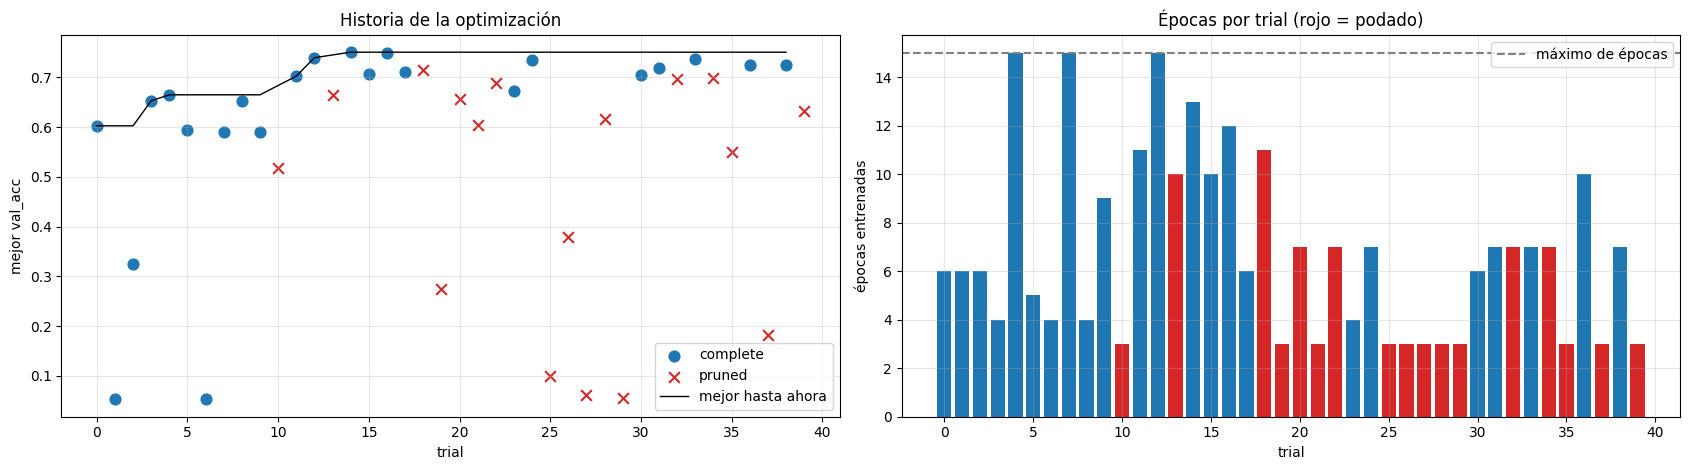

                trials  épocas_promedio  tiempo_total_s
corte                                                  
early_stopping      20              7.2           192.5
max_epochs           3             15.0            50.3
pruned              17              4.8           147.4


In [14]:
# Historia de la búsqueda y efecto del pruning
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
ax = axes[0]
for estado, marker, color in [("COMPLETE", "o", "tab:blue"), ("PRUNED", "x", "tab:red")]:
    s = df[df["estado"] == estado]
    ax.scatter(s["trial"], s["best_val_acc"], marker=marker, color=color, s=60, label=estado.lower())
ax.plot(df_ok["trial"], df_ok["best_val_acc"].cummax(), "k-", lw=1, label="mejor hasta ahora")
ax.set_xlabel("trial"); ax.set_ylabel("mejor val_acc"); ax.set_title("Historia de la optimización"); ax.legend()

ax = axes[1]
colores = df["estado"].map({"COMPLETE": "tab:blue", "PRUNED": "tab:red"})
ax.bar(df["trial"], df["épocas"], color=colores)
ax.axhline(MAX_EPOCHS_SEARCH, ls="--", c="gray", label="máximo de épocas")
ax.set_xlabel("trial"); ax.set_ylabel("épocas entrenadas"); ax.set_title("Épocas por trial (rojo = podado)"); ax.legend()
for a in axes:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(df.groupby("corte").agg(trials=("trial", "count"), épocas_promedio=("épocas", "mean"),
                              tiempo_total_s=("train_time_s", "sum")).round(1).to_string())

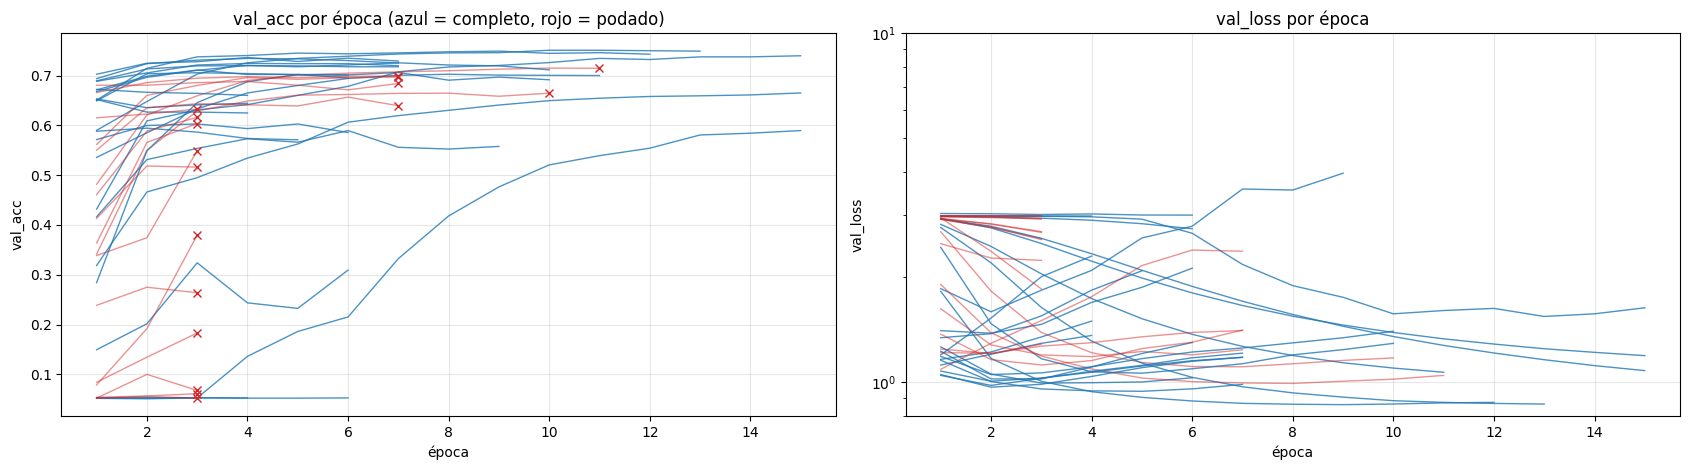

In [15]:
# Curvas de validación de TODOS los trials: se ve dónde corta el pruner
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
for t in study.trials:
    if "history" not in t.user_attrs:
        continue
    h = t.user_attrs["history"]
    ep = np.arange(1, len(h["val_acc"]) + 1)
    podado = t.state == optuna.trial.TrialState.PRUNED
    estilo = dict(color="tab:red" if podado else "tab:blue", alpha=0.5 if podado else 0.8, lw=1)
    axes[0].plot(ep, h["val_acc"], **estilo)
    axes[1].plot(ep, h["val_loss"], **estilo)
    if podado:
        axes[0].plot(ep[-1], h["val_acc"][-1], "x", color="tab:red")
axes[0].set_title("val_acc por época (azul = completo, rojo = podado)"); axes[0].set_ylabel("val_acc")
axes[1].set_title("val_loss por época"); axes[1].set_ylabel("val_loss"); axes[1].set_yscale("log")
axes[1].set_ylim(top=10)   # algún trial divergente puede tener loss enorme: recortamos el eje
for a in axes:
    a.set_xlabel("época"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

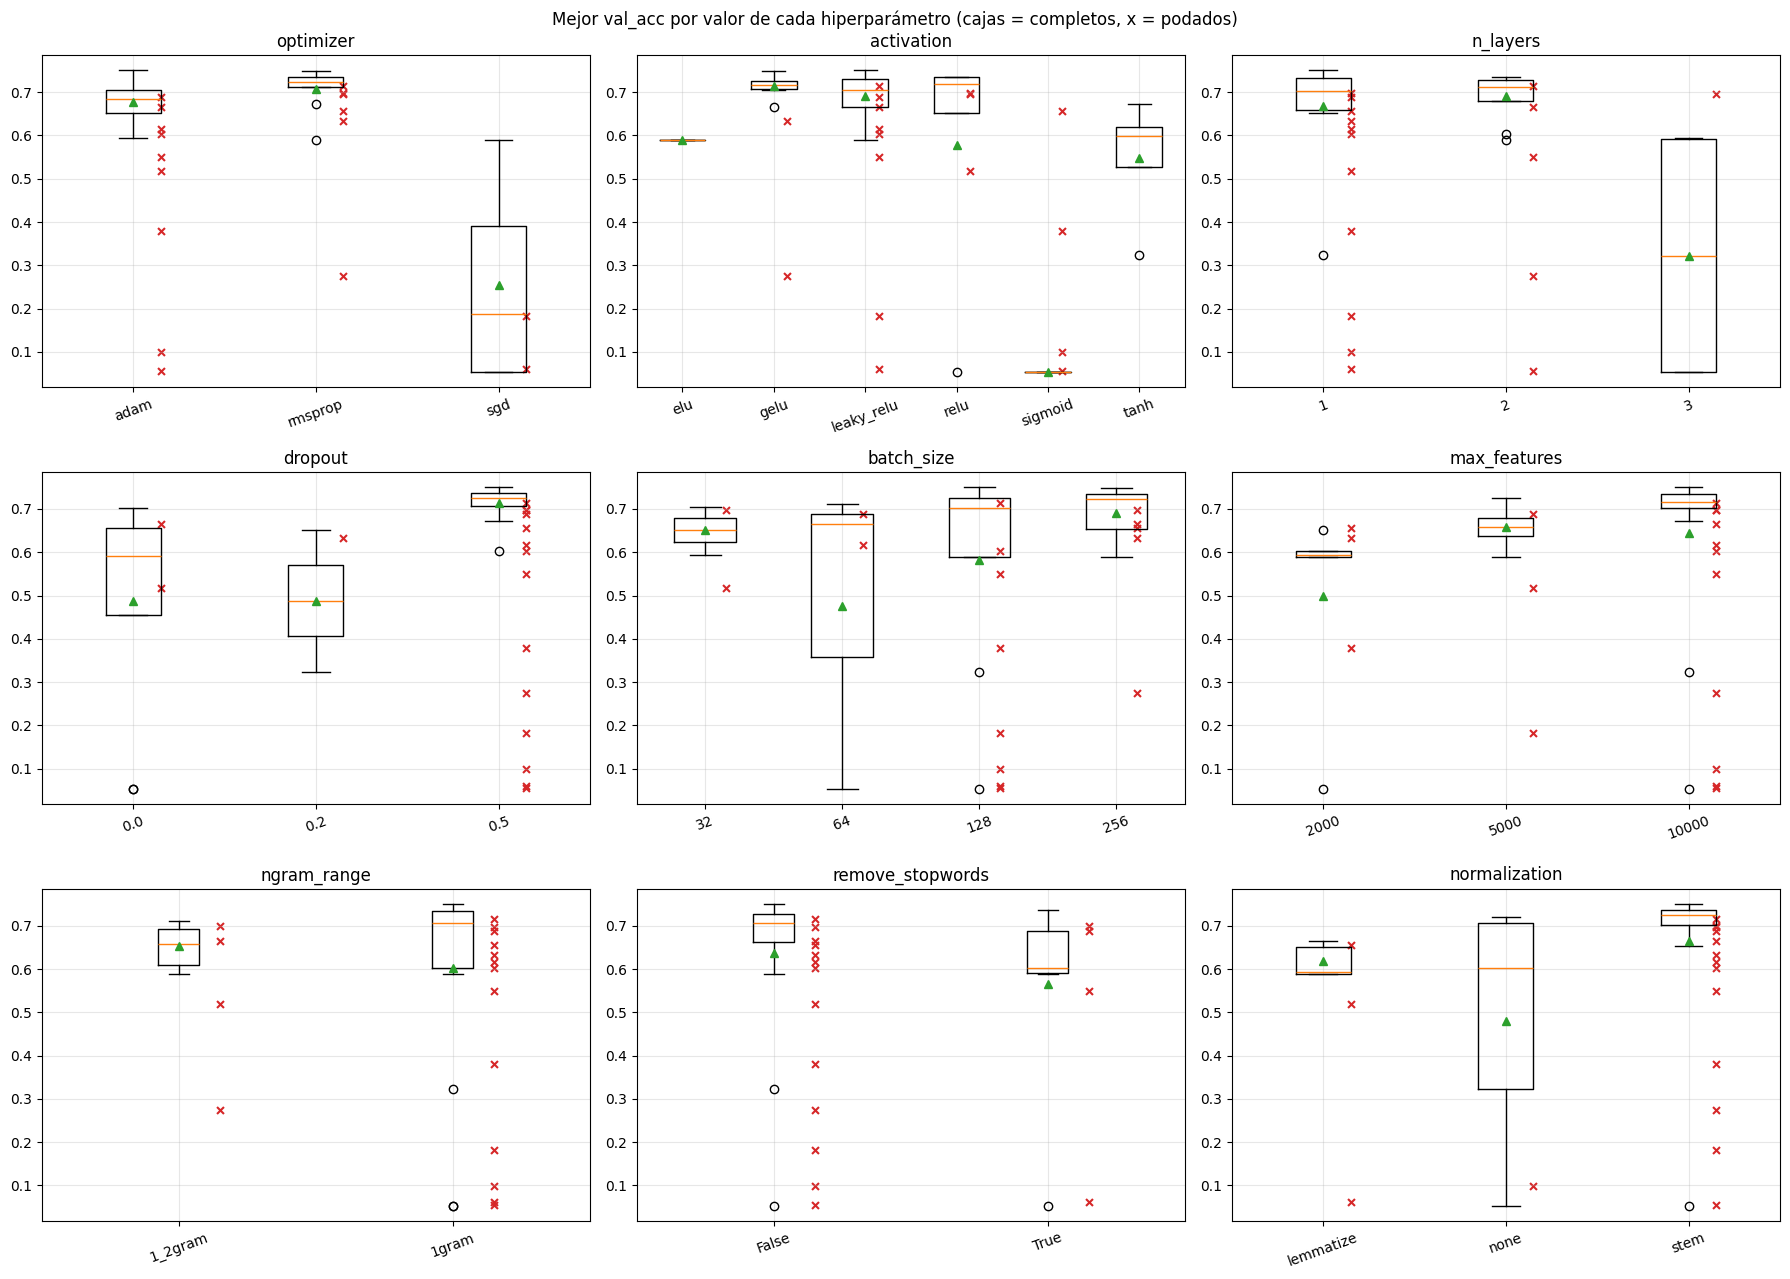


--- optimizer ---
           trials  podados  mejor_val_acc  media_completos  s_por_época
optimizer                                                              
adam           19        9         0.7508           0.6772       1.6038
rmsprop        15        6         0.7490           0.7069       1.5473
sgd             6        2         0.5895           0.2548       0.6754

--- activation ---
            trials  podados  mejor_val_acc  media_completos  s_por_época
activation                                                              
elu              1        0         0.5895           0.5895       0.3743
gelu             8        2         0.7490           0.7135       1.3111
leaky_relu      14        8         0.7508           0.6902       1.6358
relu             8        3         0.7362           0.5791       1.9419
sigmoid          5        4         0.6567           0.0526       1.0933
tanh             4        0         0.6721           0.5483       0.7418

--- n_layers ---

In [16]:
# Efecto de cada hiperparámetro (sólo trials completos; las cruces rojas son podados, con su mejor val_acc parcial)
params_cat = ["optimizer", "activation", "n_layers", "dropout", "batch_size", "max_features",
              "ngram_range", "remove_stopwords", "normalization"]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, p in zip(axes.ravel(), params_cat):
    valores = sorted(df[p].unique())   # orden natural (numérico o alfabético)
    data = [df_ok.loc[df_ok[p] == v, "best_val_acc"].values for v in valores]
    ax.boxplot([d if len(d) else [np.nan] for d in data], showmeans=True)
    ax.set_xticks(range(1, len(valores) + 1)); ax.set_xticklabels([str(v) for v in valores], rotation=20)
    for i, v in enumerate(valores):
        pr = df[(df[p] == v) & (df["estado"] == "PRUNED")]["best_val_acc"]
        ax.scatter(np.full(len(pr), i + 1.15), pr, marker="x", color="tab:red", s=25)
    ax.set_title(p); ax.grid(alpha=0.3)
plt.suptitle("Mejor val_acc por valor de cada hiperparámetro (cajas = completos, x = podados)")
plt.tight_layout(); plt.show()

for p in ["optimizer", "activation", "n_layers", "dropout"]:
    print(f"\n--- {p} ---")
    print(df.groupby(p).agg(trials=("trial", "count"),
                            podados=("estado", lambda s: int((s == "PRUNED").sum())),
                            mejor_val_acc=("best_val_acc", "max"),
                            media_completos=("best_val_acc", lambda s: s[df.loc[s.index, "estado"] == "COMPLETE"].mean()),
                            s_por_época=("s_por_época", "mean")).round(4).to_string())

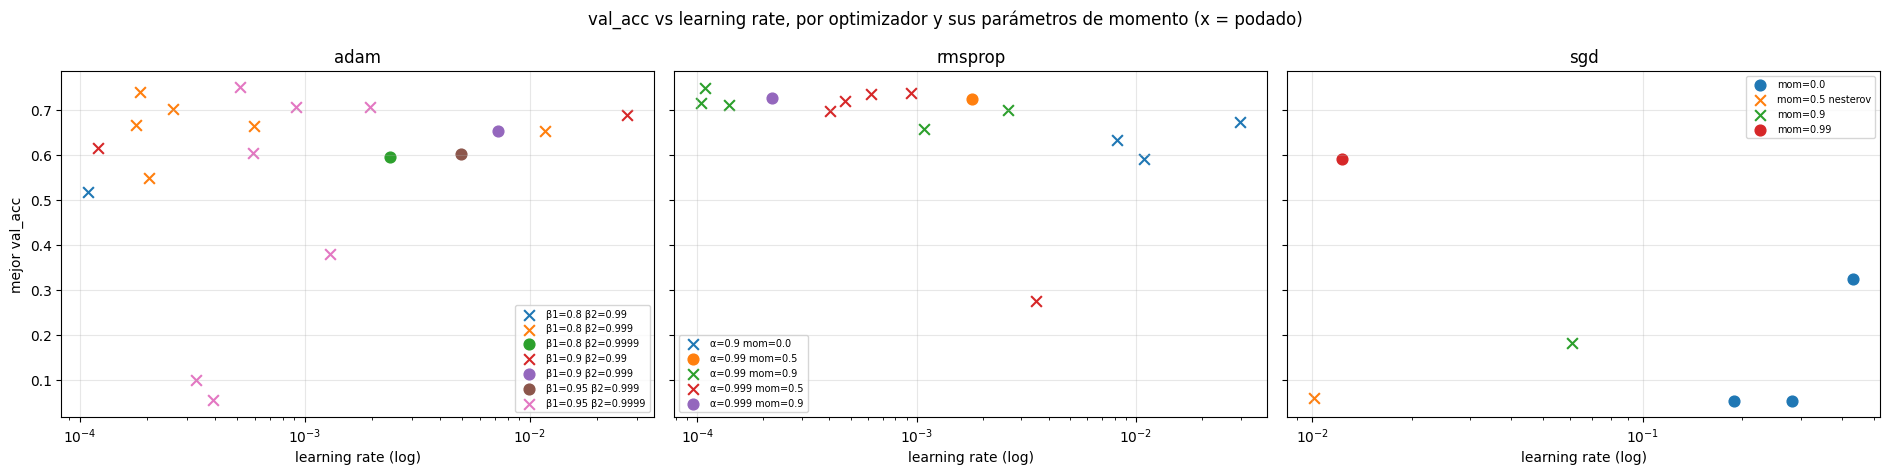

In [17]:
# Learning rate y momentos por optimizador
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), sharey=True)
for ax, opt in zip(axes, ["adam", "rmsprop", "sgd"]):
    s = df[df["optimizer"] == opt]
    for detalle, g in s.groupby("opt_params"):
        ax.scatter(g["lr"], g["best_val_acc"], s=60, label=detalle,
                   marker="o" if (g["estado"] == "COMPLETE").all() else "x")
    ax.set_xscale("log"); ax.set_xlabel("learning rate (log)"); ax.set_title(opt)
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("mejor val_acc")
plt.suptitle("val_acc vs learning rate, por optimizador y sus parámetros de momento (x = podado)")
plt.tight_layout(); plt.show()

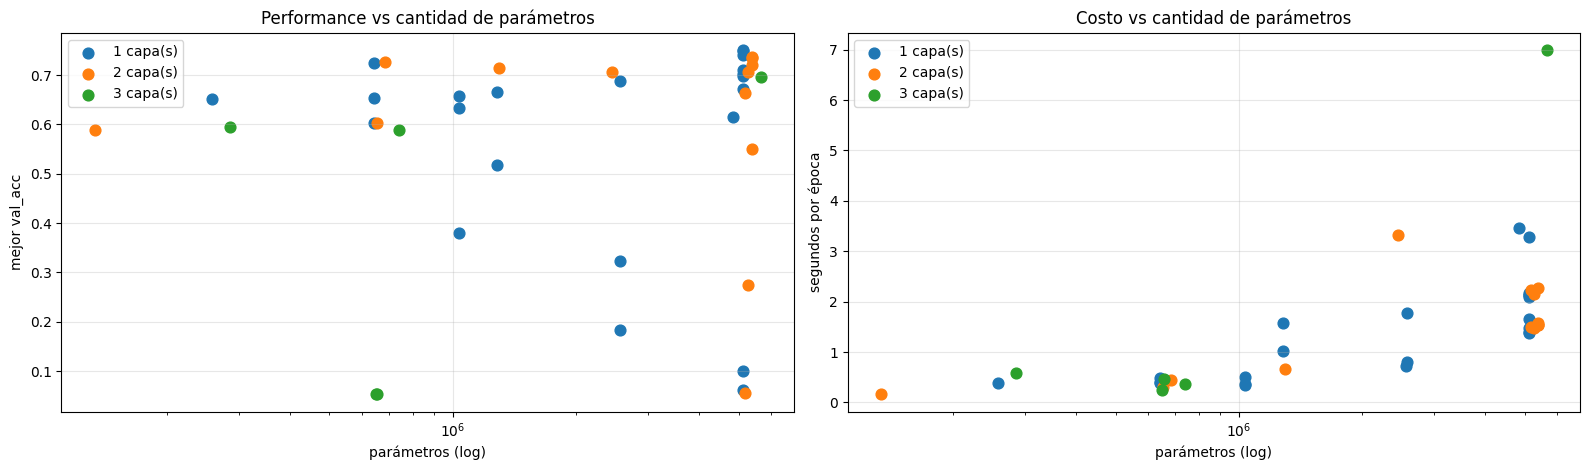

Correlación de Spearman entre parámetros y s/época: +0.77


In [18]:
# Tamaño del modelo: performance y costo
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for nl, g in df.groupby("n_layers"):
    axes[0].scatter(g["n_params"], g["best_val_acc"], s=60, label=f"{nl} capa(s)")
    axes[1].scatter(g["n_params"], g["s_por_época"], s=60, label=f"{nl} capa(s)")
axes[0].set_ylabel("mejor val_acc"); axes[0].set_title("Performance vs cantidad de parámetros")
axes[1].set_ylabel("segundos por época"); axes[1].set_title("Costo vs cantidad de parámetros")
for a in axes:
    a.set_xscale("log"); a.set_xlabel("parámetros (log)"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()
rho = df["n_params"].corr(df["s_por_época"], method="spearman")
print(f"Correlación de Spearman entre parámetros y s/época: {rho:+.2f}")

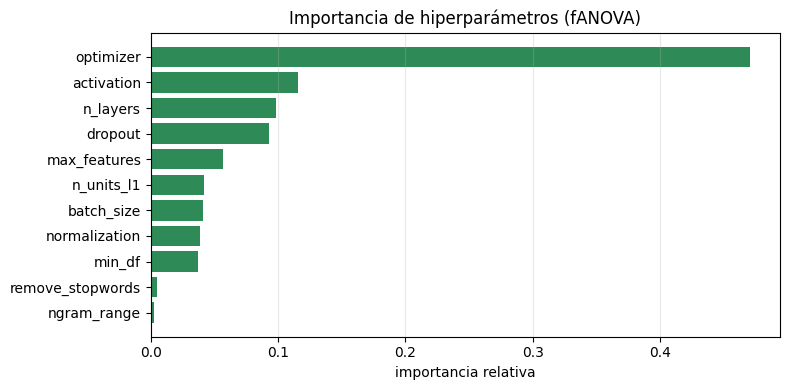

optimizer          0.471
activation         0.115
n_layers           0.099
dropout            0.093
max_features       0.057
n_units_l1         0.041
batch_size         0.041
normalization      0.039
min_df             0.037
remove_stopwords   0.005
ngram_range        0.003


In [19]:
# Importancia de hiperparámetros (fANOVA, sólo trials completos)
# Optuna sólo puede evaluar los hiperparámetros presentes en TODOS los trials completos:
# los condicionales (lr de cada optimizador, betas, momentos, n_units_l2/l3) quedan afuera.
# La semilla se pasa al evaluador fANOVA (get_param_importances no recibe `seed` directamente).
try:
    evaluador = optuna.importance.FanovaImportanceEvaluator(seed=SEED)
    importances = optuna.importance.get_param_importances(study, evaluator=evaluador)
    plt.figure(figsize=(8, 4))
    plt.barh(list(importances)[::-1], list(importances.values())[::-1], color="seagreen")
    plt.xlabel("importancia relativa"); plt.title("Importancia de hiperparámetros (fANOVA)")
    plt.grid(alpha=0.3, axis="x"); plt.tight_layout(); plt.show()
    for k, v in importances.items():
        print(f"{k:18s} {v:.3f}")
except Exception as e:
    print("No se pudo calcular la importancia:", e)

In [20]:
# BONUS: ¿cuánto tiempo ahorró el pruning?
# Para cada trial podado estimamos cuánto habría tardado si seguía hasta MAX_EPOCHS_SEARCH
# (o hasta donde lo habría cortado el early stopping, que no podemos saber: es una cota superior).
pr = df[df["estado"] == "PRUNED"]
ahorro_max = float(((MAX_EPOCHS_SEARCH - pr["épocas"]) * pr["s_por_época"]).sum())
tiempo_real = float(df["train_time_s"].sum())
print(f"Trials podados: {len(pr)} de {len(df)}")
print(f"Tiempo de entrenamiento real de la búsqueda: {tiempo_real/60:.1f} min")
print(f"Tiempo que se habría gastado sin pruning (cota superior): {(tiempo_real + ahorro_max)/60:.1f} min")
print(f"Ahorro máximo estimado: {ahorro_max/60:.1f} min ({ahorro_max/(tiempo_real + ahorro_max):.0%})")
if len(pr):
    print(f"Mejor val_acc alcanzada por un trial podado: {pr['best_val_acc'].max():.4f} "
          f"(vs mejor completo {df_ok['best_val_acc'].max():.4f})")

Trials podados: 17 de 40
Tiempo de entrenamiento real de la búsqueda: 6.5 min
Tiempo que se habría gastado sin pruning (cota superior): 11.5 min
Ahorro máximo estimado: 5.0 min (43%)
Mejor val_acc alcanzada por un trial podado: 0.7150 (vs mejor completo 0.7508)


In [21]:
# Resumen automático de la búsqueda
top = df_ok.nlargest(5, "best_val_acc")
print("TOP-5 trials completos:")
display(top[["trial", "best_val_acc", "best_epoch", "optimizer", "lr", "opt_params", "activation", "capas",
             "dropout", "batch_size", "max_features", "ngram_range", "remove_stopwords", "normalization",
             "n_params", "train_time_s"]].round(4))
for p in ["optimizer", "activation", "n_layers", "dropout", "ngram_range", "remove_stopwords"]:
    vc = top[p].astype(str).value_counts()
    print(f"  {p:17s} más frecuente en el top-5: {vc.index[0]} ({vc.iloc[0]}/5)")
print(f"\nRango de val_acc (completos): {df_ok['best_val_acc'].min():.4f} – {df_ok['best_val_acc'].max():.4f}")
print(f"Error estándar aprox. de una val_acc de {df_ok['best_val_acc'].max():.2f} con {len(idx_val)} docs: "
      f"±{np.sqrt(df_ok['best_val_acc'].max()*(1-df_ok['best_val_acc'].max())/len(idx_val)):.4f}")

TOP-5 trials completos:


,trial,best_val_acc,best_epoch,optimizer,lr,opt_params,activation,capas,dropout,batch_size,max_features,ngram_range,remove_stopwords,normalization,n_params,train_time_s
14,14,0.7508,10,adam,0.0005,β1=0.95 β2=0.9999,leaky_relu,512,0.5,128,10000,1gram,False,stem,5130772,27.2955
16,16,0.7490,9,rmsprop,0.0001,α=0.99 mom=0.9,gelu,512,0.5,256,10000,1gram,False,stem,5130772,16.6523
12,12,0.7397,15,adam,0.0002,β1=0.8 β2=0.999,leaky_relu,512,0.5,128,10000,1gram,False,stem,5130772,32.5780
33,33,0.7362,4,rmsprop,0.0009,α=0.999 mom=0.5,relu,512-512,0.5,256,10000,1gram,True,stem,5393428,10.7901
24,24,0.7344,4,rmsprop,0.0006,α=0.999 mom=0.5,relu,512-512,0.5,256,10000,1gram,False,stem,5393428,10.7483


  optimizer         más frecuente en el top-5: rmsprop (3/5)
  activation        más frecuente en el top-5: leaky_relu (2/5)
  n_layers          más frecuente en el top-5: 1 (3/5)
  dropout           más frecuente en el top-5: 0.5 (5/5)
  ngram_range       más frecuente en el top-5: 1gram (5/5)
  remove_stopwords  más frecuente en el top-5: False (4/5)

Rango de val_acc (completos): 0.0526 – 0.7508
Error estándar aprox. de una val_acc de 0.75 con 2263 docs: ±0.0091


### Análisis de la búsqueda

**Resumen**: 40 trials en **7,3 minutos**. 23 completos (20 cortados por early stopping y 3 que llegaron a las 15 épocas) y **17 podados (42%)**.

**Mejor trial (#14, val_acc = 0.7508)**:

| Grupo | Hiperparámetros |
|---|---|
| Arquitectura | 1 capa oculta de 512 neuronas, **LeakyReLU**, dropout 0.5 |
| Optimizador | **Adam**, lr = 5,1·10⁻⁴, β₁ = 0.95, β₂ = 0.9999, batch 128 |
| Preprocesamiento | sin quitar stopwords, **stem**, **unigramas**, 10.000 features, min_df = 2 |

Los tres mejores (0.7508, 0.7490 y 0.7397) están **estadísticamente empatados**: el error estándar con 2.263 documentos de validación es ±0.009.

**1. Comportamiento de TPE.** Los primeros 10 trials son aleatorios y el mejor de ellos llegó a 0.665. Desde el trial 11, TPE se concentró en la región buena (1 capa de 512, dropout 0.5, stem, unigramas, 10.000 features) y encontró 0.70–0.75 en pocos trials: el muestreo guiado claramente sirvió. A partir del trial ~18, con una mediana de referencia alta, el pruner empezó a cortar casi todo lo que no mejoraba esa región.

**2. Optimizadores**:

| Optimizador | Trials | Podados | Mejor | Media (completos) |
|---|---|---|---|---|
| Adam | 19 | 9 | **0.7508** | 0.677 |
| RMSprop | 15 | 6 | 0.7490 | **0.707** |
| SGD | 6 | 2 | 0.5895 | 0.255 |

- **Adam** logró el mejor trial y **RMSprop** fue el más **robusto** (mejor media). Ambos normalizan el paso por el momento de orden 2, lo que funciona muy bien con features TF-IDF chicos y dispersos.
- **SGD fracasó**:
  - sin momento y con lr de 0.19–0.43 quedó en el azar (0.05) o apenas por encima (0.32);
  - el único SGD razonable (#7: 0.5895) usó **momentum 0.99** con lr = 0.012, lo que da un paso efectivo ≈ lr/(1−μ) ≈ 1.2, y todavía estaba mejorando en la época 15.

  Es decir, SGD necesita el momento de orden 1 para avanzar, y aun así es mucho más lento. TPE lo aprendió: sólo le dedicó 6 de 40 trials.

**3. Momentos de orden 1 y 2.**
- **Adam**: los mejores usaron tanto β₁ = 0.95, β₂ = 0.9999 (#14) como β₁ = 0.8, β₂ = 0.999 (#12). No hay un patrón claro en las betas: el **learning rate** pesa mucho más. Los Adam con β₁ = 0.95, β₂ = 0.9999 que fallaron (#25, #29) usaban **sigmoid**, y el problema es la activación, no las betas.
- **RMSprop**: todos los del top usan **momentum 0.5–0.9** (orden 1) con α = 0.99–0.999 (orden 2). Los RMSprop sin momentum (#9, #23, #39) quedaron en 0.59–0.67. **Agregar el momento de orden 1 a RMSprop ayudó.**

**4. Learning rate.** Los mejores Adam/RMSprop están en **10⁻⁴ – 10⁻³**, un orden de magnitud **menor** que el de la softmax del TP1 (3·10⁻³). Un MLP con lr alto sobreajusta de inmediato: los trials con lr > 5·10⁻³ (#3, #8, #23) tuvieron su mejor val_acc en la **época 1**, y después el early stopping los cortó.

**5. Activaciones**:

| Activación | Trials | Podados | Mejor | Media (completos) |
|---|---|---|---|---|
| LeakyReLU | 14 | 8 | **0.7508** | 0.690 |
| GELU | 8 | 2 | 0.7490 | **0.714** |
| ReLU | 8 | 3 | 0.7362 | 0.579 |
| Tanh | 4 | 0 | 0.6721 | 0.548 |
| Sigmoid | 5 | **4** | 0.6567 | 0.053 |
| ELU | 1 | 0 | 0.5895 | — (un solo trial, no concluyente) |

- Las de la familia ReLU y GELU dominan.
- **Sigmoid** fue la peor: 4 de 5 trials podados, y el único completo quedó en el azar (con SGD y 3 capas). Su derivada vale como mucho 0.25 y se satura: el gradiente se desvanece al atravesar capas. Con 1 capa y RMSprop llegó a 0.657, así que puede entrenar, pero peor.
- **Tanh** quedó en el medio: está centrada en 0, pero también se satura.

**6. Capas.** **1 capa oculta fue lo mejor** (0.7508), 2 capas llegaron a 0.736 y 3 capas a 0.697 (#32, podado). Con TF-IDF, la información relevante es "qué palabras aparecen", y la primera capa ya la captura. Las capas extra suman costo y sobreajuste, no accuracy. Las medias de 3 capas (0.32) están además arrastradas por trials con SGD o sigmoid.

**7. Dropout: muy favorecido.** 27 de 40 trials usaron 0.5, y **los 5 mejores usan 0.5**. La media de los completos es 0.714 con 0.5 contra 0.488 con 0.0.
- Con 512 neuronas y 5 M de parámetros para 9.000 documentos, el dropout frena la memorización y permite entrenar **más épocas** antes de sobreajustar. Los mejores (#14, #16, #12) alcanzaron su máximo en las épocas 10, 9 y 15, mientras que los trials sin dropout y lr alto lo hicieron en la época 1.

**8. Preprocesamiento.** Los 5 mejores usan **stem + unigramas + 10.000 features**, igual que el TP1.
- Los bigramas rindieron peor (el mejor llegó a 0.711), y ningún trial con 2.000 features superó 0.657.
- Las stopwords no importan: el #33 (quitándolas) y el #24 (dejándolas), con todo lo demás casi igual, dan 0.736 y 0.734. En el TP1 también era un empate.

**9. Tiempos.** El costo por época crece con los parámetros (Spearman +0.77): desde 0.16 s/época (133 k parámetros) hasta 7.0 s/época (#32: 3×512 con batch 32).
- **La primera capa domina**: 1×512 tiene 5.13 M de parámetros y 2×512 tiene 5.39 M, apenas un 5% más. Lo que más encarece es el ancho de la primera capa ($10.000 \times h_1$) y los batch chicos (más pasos por época).

**10. Bonus: pruning.** Según la celda de ahorro:
- Los 17 trials podados entrenaron 147 s. Si hubieran llegado a las 15 épocas, habrían costado hasta **5,0 min más**.
- Tiempo total de entrenamiento de la búsqueda: 6,5 min reales, contra ~11,5 min sin pruning (**ahorro ≈ 43%**).
- Sumando el early stopping (otros ~3,0 min ahorrados), la búsqueda sin ninguno de los dos habría tardado ~14,5 min: entre ambos ahorraron **más de la mitad del tiempo**.
- **Costo del pruning**: el mejor trial podado (#18, RMSprop, 2×128) iba en 0.715 cuando lo cortaron en la época 11. Era competitivo pero no estaba en el top (0.73–0.75), así que no se perdió nada importante. El trial más caro (#32, 3 capas, 7.0 s/época) fue podado en la época 7 y ahorró ~55 segundos por sí solo.

**11. Importancia de hiperparámetros (fANOVA).**

| Hiperparámetro | Importancia |
|---|---|
| optimizer | **0.47** |
| activation | 0.12 |
| n_layers | 0.10 |
| dropout | 0.09 |
| max_features | 0.06 |
| n_units_l1, batch_size | 0.04 c/u |
| normalization, min_df | 0.04 c/u |
| remove_stopwords, ngram_range | < 0.01 |

- **El optimizador explica casi la mitad de la variación de la val_acc.** Es básicamente la diferencia entre SGD (que fracasó) y los optimizadores con momento de orden 2. Lo siguen la activación (sobre todo, el efecto de sigmoid) y la arquitectura (capas y dropout).
- **El preprocesamiento pesa poco**, y stopwords y n-gramas casi nada. Coincide con los empates que vimos tanto acá como en el TP1.
- **Limitaciones**:
  - fANOVA sólo evalúa los hiperparámetros presentes en **todos** los trials completos. Los condicionales (el learning rate de cada optimizador, las betas, los momentos, `n_units_l2/l3`) quedan afuera, y el lr fue muy determinante (punto 4).
  - Con 23 trials completos la estimación es ruidosa.
  - El valor bajo de `ngram_range` no contradice que los bigramas rindieran peor: hubo pocos trials completos con bigramas, y en ellos el efecto se mezcla con el del optimizador y la activación.

## 7. Entrenamiento final y evaluación en test

Entrenamos la mejor configuración con **todo el train** (11.314 documentos) y la evaluamos en el **test**, que no se usó en la búsqueda.

La cantidad de épocas es la `best_epoch` del mejor trial: se eligió con **validación**, no mirando el test. En el TP1 se entrenaban 20 épocas fijas y el test mostraba que el óptimo estaba antes. El "val" del log de esta celda es el test, y se usa sólo para monitorear.

Se registra en TensorBoard (`runs/mlp_final`) y en MLflow (experimento `mlp_20newsgroups`, con el modelo serializado).

In [22]:
# Entrenamiento final con los mejores hiperparámetros
bt = study.best_trial
bp = bt.params
BEST_HIDDEN = bt.user_attrs["hidden"]
BEST_EPOCHS = bt.user_attrs["best_epoch"]   # cantidad de épocas elegida con VALIDACIÓN (no con test)
BEST_NGRAM = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
if bp["optimizer"] == "adam":
    opt_kw = {"beta1": bp["adam_beta1"], "beta2": bp["adam_beta2"]}
elif bp["optimizer"] == "rmsprop":
    opt_kw = {"alpha": bp["rmsprop_alpha"], "momentum": bp["rmsprop_momentum"]}
else:
    opt_kw = {"momentum": bp["sgd_momentum"], "nesterov": bp.get("sgd_nesterov", False)}
BEST_LR = bt.user_attrs["lr"]
print("Arquitectura:", BEST_HIDDEN, "| activación:", bp["activation"], "| dropout:", bp["dropout"])
print("Optimizador:", bp["optimizer"], "lr =", f"{BEST_LR:.2e}", opt_kw, "| batch:", bp["batch_size"],
      "| épocas:", BEST_EPOCHS)

train_texts_final, test_texts_final = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, bp["max_features"], bp["min_df"])

torch.manual_seed(SEED)
train_loader_final = DataLoader(to_tensor_dataset(X_train_final, y_train_all), batch_size=bp["batch_size"], shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, y_test), batch_size=1024, shuffle=False)

model = MLP(X_train_final.shape[1], BEST_HIDDEN, NUM_CLASSES, activation=bp["activation"], dropout=bp["dropout"])
optimizer = make_optimizer(bp["optimizer"], model.parameters(), BEST_LR, **opt_kw)
writer = SummaryWriter(log_dir="runs/mlp_final")

mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups")
with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**bp, "epochs": BEST_EPOCHS, "n_params": count_params(model)})
    history_final = train_model(model, train_loader_final, test_loader_final, optimizer,
                                epochs=BEST_EPOCHS, writer=writer, run_name="final")
    input_example = X_test_final[:5].astype(np.float32).toarray()
    mlflow.pytorch.log_model(model.cpu(), "model", input_example=input_example)
writer.close()
model.to(device)
print(f"Tiempo de entrenamiento final: {sum(history_final['epoch_time']):.1f}s")

Arquitectura: [512] | activación: leaky_relu | dropout: 0.5
Optimizador: adam lr = 5.14e-04 {'beta1': 0.95, 'beta2': 0.9999} | batch: 128 | épocas: 10
[final] Epoch 1/10 - train_loss: 2.8800 train_acc: 0.3817 - val_loss: 2.6854 val_acc: 0.5871 - 2.9s
[final] Epoch 2/10 - train_loss: 2.2487 train_acc: 0.6711 - val_loss: 1.9791 val_acc: 0.6346 - 2.9s
[final] Epoch 3/10 - train_loss: 1.5147 train_acc: 0.7430 - val_loss: 1.4998 val_acc: 0.6718 - 2.8s
[final] Epoch 4/10 - train_loss: 1.0790 train_acc: 0.7968 - val_loss: 1.2772 val_acc: 0.6803 - 2.8s
[final] Epoch 5/10 - train_loss: 0.8382 train_acc: 0.8260 - val_loss: 1.1663 val_acc: 0.6909 - 2.9s
[final] Epoch 6/10 - train_loss: 0.6827 train_acc: 0.8563 - val_loss: 1.1085 val_acc: 0.6953 - 3.1s
[final] Epoch 7/10 - train_loss: 0.5694 train_acc: 0.8790 - val_loss: 1.0717 val_acc: 0.6950 - 3.3s
[final] Epoch 8/10 - train_loss: 0.4847 train_acc: 0.8946 - val_loss: 1.0567 val_acc: 0.6949 - 3.5s
[final] Epoch 9/10 - train_loss: 0.4191 train_acc

2026/10/20 01:21:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


[final] Epoch 10/10 - train_loss: 0.3648 train_acc: 0.9250 - val_loss: 1.0444 val_acc: 0.6950 - 2.8s


Tiempo de entrenamiento final: 30.5s


In [23]:
%load_ext tensorboard
%tensorboard --logdir runs

Reusing TensorBoard on port 6006 (pid 28432), started 5 days, 0:30:55 ago. (Use '!kill 28432' to kill it.)

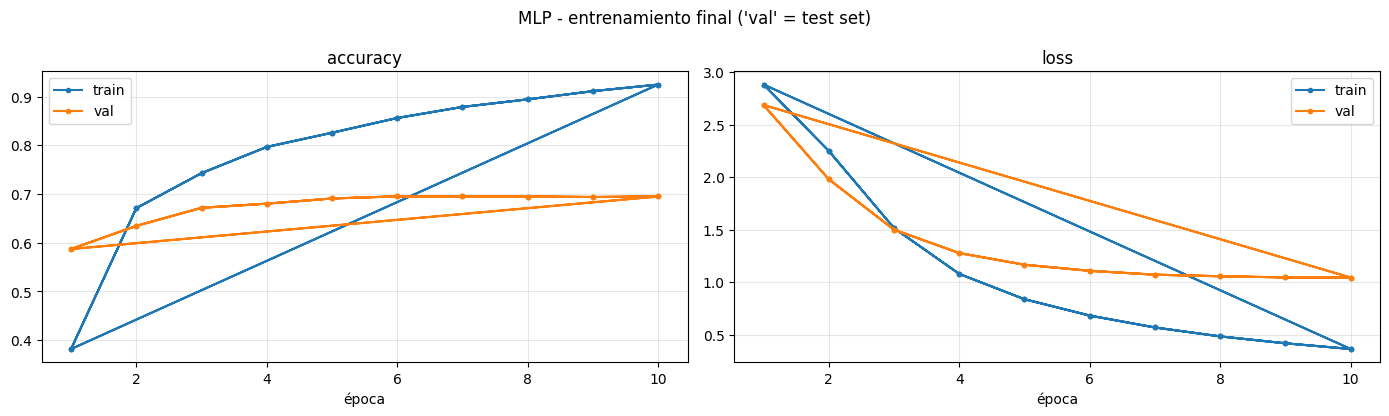

In [24]:
# Las mismas curvas de TensorBoard como imagen estática (para que se vean en GitHub)
graficar_tensorboard("runs/mlp_final", "MLP - entrenamiento final ('val' = test set)")

In [25]:
SOFTMAX_TP1_TEST_ACC = 0.6682   # resultado del TP1 (regresión softmax) para comparar

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        all_preds.extend(model(xb.to(device)).argmax(dim=1).cpu().numpy())
        all_labels.extend(yb.numpy())
all_preds, all_labels = np.array(all_preds), np.array(all_labels)

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test MLP: {test_accuracy:.4f}  |  Softmax TP1: {SOFTMAX_TP1_TEST_ACC:.4f}  |  "
      f"diferencia: {test_accuracy - SOFTMAX_TP1_TEST_ACC:+.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

Accuracy en test MLP: 0.6950  |  Softmax TP1: 0.6682  |  diferencia: +0.0268

                          precision    recall  f1-score   support

             alt.atheism       0.48      0.56      0.52       319
           comp.graphics       0.64      0.67      0.65       389
 comp.os.ms-windows.misc       0.62      0.64      0.63       394
comp.sys.ibm.pc.hardware       0.64      0.65      0.64       392
   comp.sys.mac.hardware       0.72      0.70      0.71       385
          comp.windows.x       0.81      0.67      0.73       395
            misc.forsale       0.79      0.78      0.79       390
               rec.autos       0.74      0.73      0.74       396
         rec.motorcycles       0.80      0.74      0.77       398
      rec.sport.baseball       0.57      0.85      0.69       397
        rec.sport.hockey       0.92      0.89      0.90       399
               sci.crypt       0.81      0.72      0.76       396
         sci.electronics       0.64      0.58      0.61       3

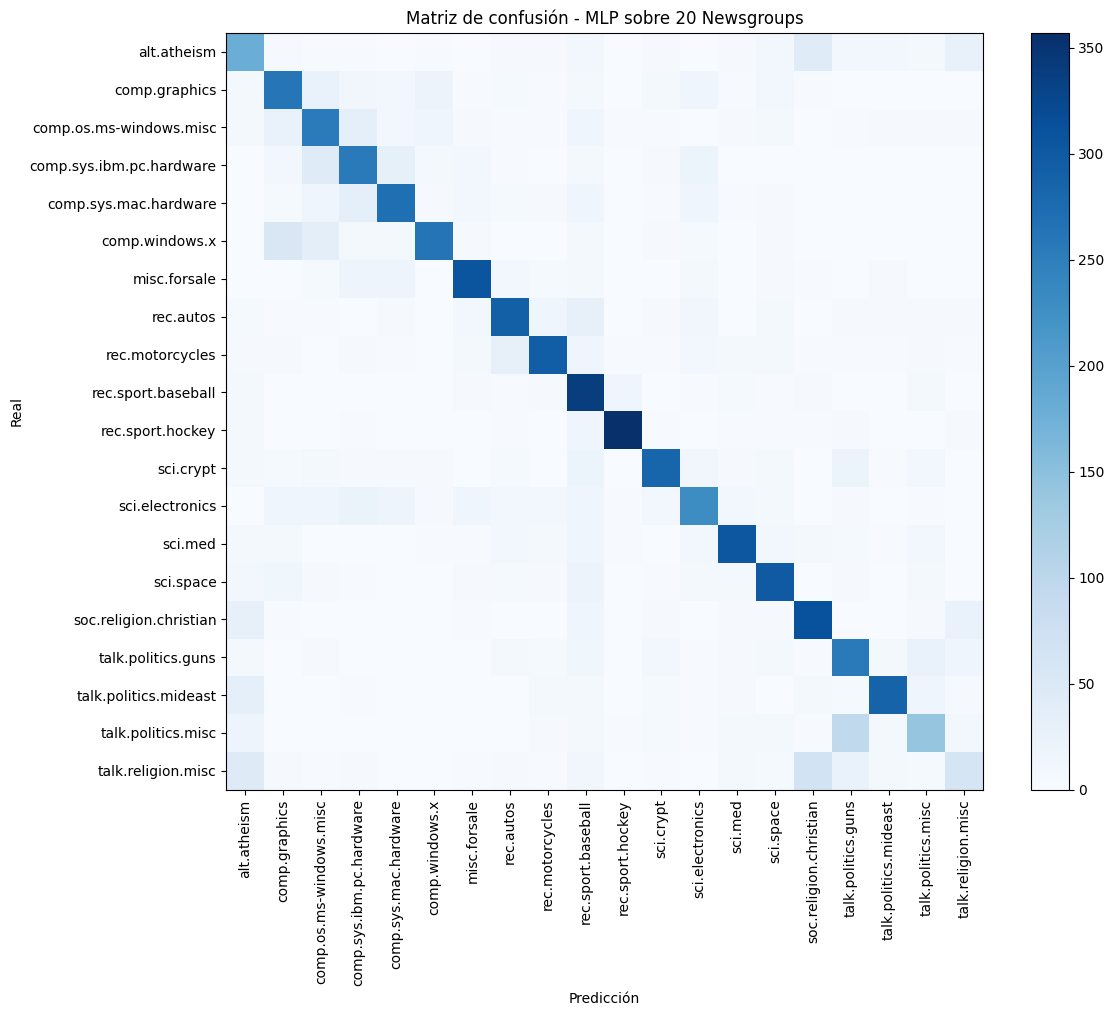

Top 8 confusiones (real -> predicho):
  talk.politics.misc         -> talk.politics.guns           94 docs (30.3%)
  talk.religion.misc         -> soc.religion.christian       66 docs (26.3%)
  comp.windows.x             -> comp.graphics                53 docs (13.4%)
  talk.religion.misc         -> alt.atheism                  44 docs (17.5%)
  alt.atheism                -> soc.religion.christian       43 docs (13.5%)
  comp.sys.ibm.pc.hardware   -> comp.os.ms-windows.misc      42 docs (10.7%)
  comp.windows.x             -> comp.os.ms-windows.misc      34 docs (8.6%)
  comp.sys.mac.hardware      -> comp.sys.ibm.pc.hardware     33 docs (8.6%)


In [26]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout(); plt.show()

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pares = sorted(((cm_off[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0), reverse=True)
print("Top 8 confusiones (real -> predicho):")
for n, i, j in pares[:8]:
    print(f"  {class_names[i]:26s} -> {class_names[j]:26s} {n:4d} docs ({n / cm[i].sum():.1%})")

### Análisis del entrenamiento final y la evaluación

**Entrenamiento.** Se entrenaron **10 épocas** (la mejor época del trial #14, elegida con validación), en 30,5 s (3,1 s/época).
- La accuracy de test sube hasta ~0.695 en la época 6 y queda **estable** hasta la 10 (0.6950).
- La test_loss **sigue bajando** hasta el final (1.044).

A diferencia del TP1, donde con 20 épocas fijas la test_acc caía desde la época 7, acá no hay señales de sobreajuste. Elegir las épocas con validación funcionó.

**Resultado en test: 0.6950 vs 0.6682 de la softmax del TP1 (+2,7 puntos).** Con 7.532 documentos de test, el error estándar es ≈ ±0.005, así que la mejora es real, aunque modesta. La macro-F1 pasa de 0.66 a 0.68.

**Validación (0.751) vs test (0.695).** Hay 5,6 puntos de diferencia, por las mismas razones que en el TP1:
- el test es **temporalmente posterior** al train (split "bydate"), mientras que la validación salió al azar del propio train;
- hay sesgo de selección al elegir el mejor de 40 trials.

La brecha es algo menor que en el TP1 (7 puntos).

**Por clase (MLP vs softmax TP1, F1):**
- **Mejoran**:
  - `talk.politics.mideast`: 0.77 → 0.80
  - `misc.forsale`: 0.75 → 0.79
  - `sci.med`: 0.75 → 0.79
  - `rec.sport.hockey`: 0.88 → 0.90
  - `alt.atheism`: 0.49 → 0.52
  - `sci.electronics`: 0.58 → 0.61
- **Empeora**: `talk.religion.misc`, 0.34 → **0.29**, con recall de apenas 0.24. El MLP manda todavía más documentos de esa clase "cajón de sastre" a sus vecinas grandes.
- **Persiste el artefacto de `rec.sport.baseball`**: precision 0.57 y recall 0.85, el mismo patrón del TP1. Es consistente con que la causa sean los documentos vacíos, que ningún modelo puede clasificar: con un vector nulo, el MLP también responde siempre lo mismo.

**Confusiones**: los mismos bloques temáticos que el TP1.

| Real → Predicho | Docs | % de la clase real |
|---|---|---|
| `talk.politics.misc` → `talk.politics.guns` | 94 | 30% |
| `talk.religion.misc` → `soc.religion.christian` | 66 | 26% |
| `comp.windows.x` → `comp.graphics` | 53 | — |
| `talk.religion.misc` → `alt.atheism` | 44 | — |
| `alt.atheism` → `soc.religion.christian` | 43 | — |
| `comp.sys.ibm.pc.hardware` → `comp.os.ms-windows.misc` | 42 | — |

El MLP mejora la accuracy global, pero **no resuelve las confusiones de fondo**: vienen del vocabulario compartido y de las categorías "misc", algo que una bolsa de palabras no puede separar, tenga o no capas ocultas. Coincide con lo que se respondió en la pregunta 10 del TP1.

## 8. Experimento de sobreajuste

**Objetivo**: encontrar una cantidad de capas y unidades ocultas con la que el modelo **sobreajuste**. Sobreajustar significa que el modelo memoriza el train (train_acc → 1, train_loss → 0) mientras la performance en validación deja de mejorar o empeora. La señal más clara es que **la val_loss sube** y la **brecha train−val** crece.

**Diseño**: fijamos todo (representación de la mejor configuración, Adam con lr = $10^{-3}$, batch 64, ReLU, **sin dropout ni weight decay**, 20 épocas) y sólo variamos la **capacidad**:

| Modelo | Parámetros aprox. (con 10.000 features) |
|---|---|
| softmax (0 capas) | 0,2 M |
| 1×64 | 0,64 M |
| 1×512 | 5,1 M |
| 2×1024 | 11,3 M |
| 3×1024 | 12,3 M |
| 3×1024 + dropout 0.5 | 12,3 M (regularizado) |

El último caso usa el mismo modelo grande con dropout, para ver si la regularización frena el sobreajuste.


In [27]:
# Experimento de sobreajuste: misma representación y optimizador, sólo cambia la CAPACIDAD del modelo
EPOCHS_OVERFIT = 20   
OVERFIT_CONFIGS = [
    # nombre,                  capas ocultas,        dropout
    ("softmax (0 capas)",      [],                   0.0),
    ("1x64",                   [64],                 0.0),
    ("1x512",                  [512],                0.0),
    ("2x1024",                 [1024, 1024],         0.0),
    ("3x1024",                 [1024, 1024, 1024],   0.0),
    ("3x1024 + dropout 0.5",   [1024, 1024, 1024],   0.5),   # mismo modelo grande, regularizado
]

# Representación: la de la mejor configuración de la búsqueda
X_tr_o, X_val_o, _ = get_representation(bp["remove_stopwords"], bp["normalization"], BEST_NGRAM,
                                         bp["max_features"], bp["min_df"])
train_ds_o, val_ds_o = to_tensor_dataset(X_tr_o, y_tr), to_tensor_dataset(X_val_o, y_val)

overfit_results = {}
mlflow.set_experiment("mlp_20newsgroups_overfit")
for name, hidden, drop in OVERFIT_CONFIGS:
    torch.manual_seed(SEED)
    m = MLP(X_tr_o.shape[1], hidden, NUM_CLASSES, activation="relu", dropout=drop)
    opt_o = optim.Adam(m.parameters(), lr=1e-3)      # Adam estándar, sin weight decay
    tl = DataLoader(train_ds_o, batch_size=64, shuffle=True)
    vl = DataLoader(val_ds_o, batch_size=1024, shuffle=False)
    w = SummaryWriter(log_dir=f"runs/overfit/{name.replace(' ', '_')}")
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"hidden": str(hidden), "dropout": drop, "n_params": count_params(m)})
        h = train_model(m, tl, vl, opt_o, EPOCHS_OVERFIT, writer=w, run_name=name, verbose=False)
    w.close()
    overfit_results[name] = {"history": h, "n_params": count_params(m), "hidden": hidden, "dropout": drop}
    print(f"{name:22s} params={count_params(m):>11,d} | train_acc final={h['train_acc'][-1]:.4f} "
          f"| best val_acc={max(h['val_acc']):.4f} (ép {int(np.argmax(h['val_acc']))+1}) "
          f"| {np.mean(h['epoch_time']):.1f}s/época")
    del m, opt_o

softmax (0 capas)      params=    200,020 | train_acc final=0.9040 | best val_acc=0.7265 (ép 19) | 0.4s/época
1x64                   params=    641,364 | train_acc final=0.9739 | best val_acc=0.7525 (ép 7) | 0.7s/época
1x512                  params=  5,130,772 | train_acc final=0.9740 | best val_acc=0.7459 (ép 3) | 3.5s/época
2x1024                 params= 11,311,124 | train_acc final=0.9749 | best val_acc=0.7190 (ép 20) | 7.4s/época
3x1024                 params= 12,360,724 | train_acc final=0.9739 | best val_acc=0.6748 (ép 12) | 8.2s/época
3x1024 + dropout 0.5   params= 12,360,724 | train_acc final=0.9690 | best val_acc=0.6867 (ép 7) | 8.6s/época


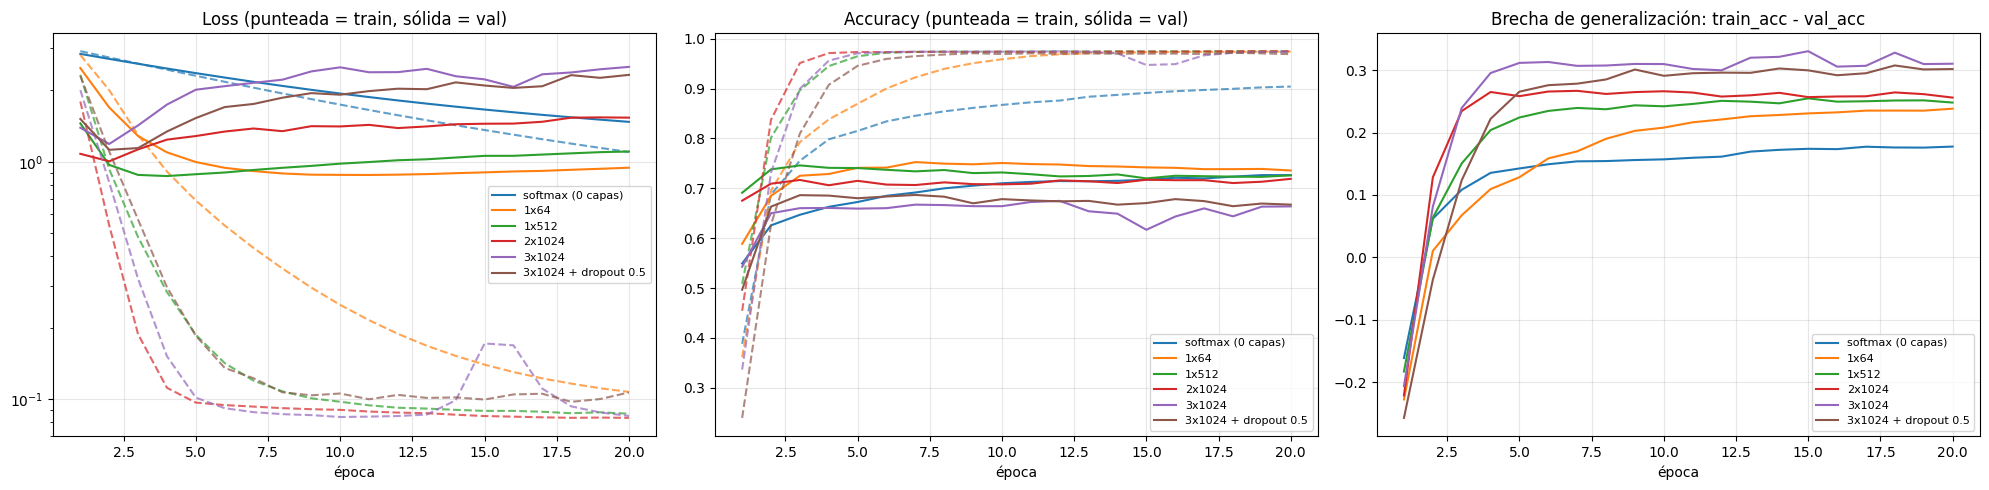

,modelo,parámetros,train_acc_final,train_loss_final,mejor_val_acc,época_mejor_val_acc,val_acc_final,época_min_val_loss,val_loss_final/min,brecha_final,s_por_época
0,softmax (0 capas),200020,0.9040,1.0988,0.7265,19,0.7265,20,1.0000,0.1775,0.4098
1,1x64,641364,0.9739,0.1073,0.7525,7,0.7357,11,1.0731,0.2382,0.6940
2,1x512,5130772,0.9740,0.0868,0.7459,3,0.7260,4,1.2686,0.2480,3.4809
3,2x1024,11311124,0.9749,0.0834,0.7190,20,0.7190,2,1.5272,0.2560,7.3989
4,3x1024,12360724,0.9739,0.0850,0.6748,12,0.6637,2,2.1119,0.3102,8.2425
5,3x1024 + dropout 0.5,12360724,0.9690,0.1068,0.6867,7,0.6673,2,2.0681,0.3017,8.6338


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for i, (name, r) in enumerate(overfit_results.items()):
    h, c = r["history"], f"C{i}"
    ep = np.arange(1, len(h["val_acc"]) + 1)
    axes[0].plot(ep, h["train_loss"], "--", color=c, alpha=0.7)
    axes[0].plot(ep, h["val_loss"], "-", color=c, label=name)
    axes[1].plot(ep, h["train_acc"], "--", color=c, alpha=0.7)
    axes[1].plot(ep, h["val_acc"], "-", color=c, label=name)
    axes[2].plot(ep, np.array(h["train_acc"]) - np.array(h["val_acc"]), color=c, label=name)
axes[0].set_yscale("log"); axes[0].set_title("Loss (punteada = train, sólida = val)")
axes[1].set_title("Accuracy (punteada = train, sólida = val)")
axes[2].set_title("Brecha de generalización: train_acc - val_acc")
for a in axes:
    a.set_xlabel("época"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for name, r in overfit_results.items():
    h = r["history"]
    vl = np.array(h["val_loss"])
    rows.append({"modelo": name, "parámetros": r["n_params"], "train_acc_final": h["train_acc"][-1],
                 "train_loss_final": h["train_loss"][-1], "mejor_val_acc": max(h["val_acc"]),
                 "época_mejor_val_acc": int(np.argmax(h["val_acc"])) + 1, "val_acc_final": h["val_acc"][-1],
                 "época_min_val_loss": int(vl.argmin()) + 1, "val_loss_final/min": vl[-1] / vl.min(),
                 "brecha_final": h["train_acc"][-1] - h["val_acc"][-1], "s_por_época": np.mean(h["epoch_time"])})
df_over = pd.DataFrame(rows)
display(df_over.round(4))

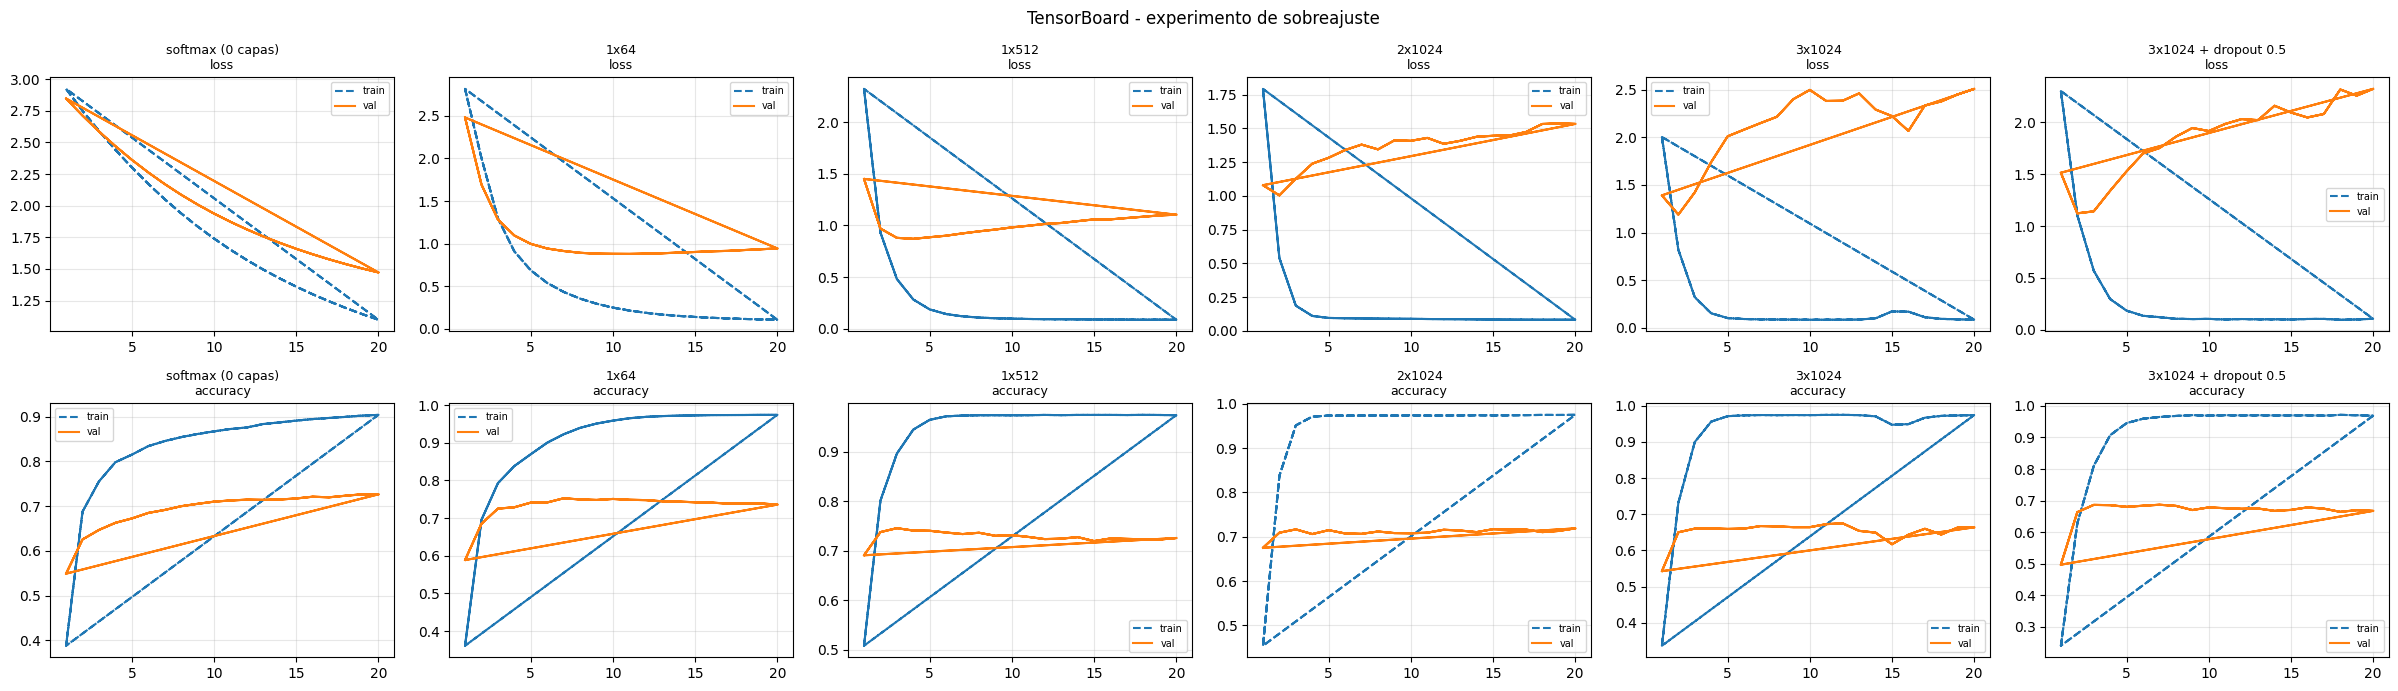

In [29]:
# Las curvas de TensorBoard del experimento de sobreajuste, como imagen estática (para GitHub)
nombres = list(overfit_results)
fig, axes = plt.subplots(2, len(nombres), figsize=(4 * len(nombres), 7), squeeze=False)
for j, name in enumerate(nombres):
    curvas = leer_scalars_tensorboard(f"runs/overfit/{name.replace(' ', '_')}")
    for i, g in enumerate(["loss", "accuracy"]):
        for split in ["train", "val"]:
            if f"{g}_{split}" in curvas:
                x, y = curvas[f"{g}_{split}"]
                axes[i, j].plot(x, y, "--" if split == "train" else "-", label=split)
        axes[i, j].set_title(f"{name}\n{g}", fontsize=9); axes[i, j].grid(alpha=0.3); axes[i, j].legend(fontsize=7)
plt.suptitle("TensorBoard - experimento de sobreajuste"); plt.tight_layout(); plt.show()

### Análisis del experimento de sobreajuste

| Modelo | Parámetros | Mejor val_acc (época) | Época de val_loss mínima | val_loss final / mínima | Brecha final | s/época |
|---|---|---|---|---|---|---|
| softmax (0 capas) | 0,2 M | 0.7265 (19) | 20 | 1.00 | 0.18 | 0.41 |
| 1×64 | 0,64 M | **0.7525** (7) | 11 | 1.07 | 0.24 | 0.69 |
| 1×512 | 5,1 M | 0.7459 (3) | 4 | 1.27 | 0.25 | 3.48 |
| 2×1024 | 11,3 M | 0.7190 (20) | 2 | 1.53 | 0.26 | 7.40 |
| **3×1024** | **12,4 M** | **0.6748** (12) | **2** | **2.11** | **0.31** | 8.24 |
| 3×1024 + dropout 0.5 | 12,4 M | 0.6867 (7) | 2 | 2.07 | 0.30 | 8.63 |

**El modelo sobreajustado es el de 3 capas de 1024 neuronas (12,4 M de parámetros).**
- Llega al techo de train_acc (0.974) en ~3 épocas y la train_loss baja a 0.085.
- Su **val_loss tiene el mínimo en la época 2 y después se duplica** (×2.11).
- La brecha train−val es la más grande (0.31).
- Su mejor val_acc (0.675) queda **casi 8 puntos por debajo** del MLP de 1×64.

Más capacidad, peor generalización: es la definición de sobreajuste.

**La tendencia es monótona con la capacidad.** A medida que crece el modelo:
- la val_loss alcanza su mínimo **antes** (época 20 → 11 → 4 → 2 → 2);
- la val_loss **sube más** después de ese mínimo (×1.00 → ×1.07 → ×1.27 → ×1.53 → ×2.11);
- la brecha crece (0.18 → 0.31).

En el gráfico de loss se ve claramente: las val_loss de 2×1024 y 3×1024 suben época tras época mientras su train_loss ya está en ~0.09. El 3×1024 muestra además inestabilidad (un salto de la train_loss cerca de la época 15).

**La train_acc no llega a 1** en ningún modelo: se plantan en ~0.974. Ese ~2,6% de documentos que ningún modelo logra acertar coincide con la fracción de documentos que quedan **vacíos** tras el preprocesamiento: son vectores de ceros y no se pueden acertar todos. Por eso la señal de sobreajuste es la **val_loss**, no la train_acc.

**Loss vs accuracy.** En el 3×1024 la val_loss se duplica, pero la val_acc "sólo" pierde algunos puntos. El modelo se vuelve **sobreconfiado**: los documentos que clasifica mal los clasifica mal con probabilidad ≈ 1, y eso dispara la entropía cruzada aunque el argmax cambie poco.

**Dropout en el modelo grande.** Mejoró la val_acc apenas (+1,2 puntos: 0.675 → 0.687), pero **no frenó la suba de la val_loss** (×2.07 contra ×2.11). El dropout se aplica después de cada capa oculta, pero la memorización ocurre sobre todo en la **primera capa** ($10.000 \times 1024$ pesos conectados directamente a las palabras). Para un modelo así haría falta regularizar esa capa: *weight decay* (`AdamW`), dropout sobre la entrada o, simplemente, menos neuronas. En la búsqueda, el dropout 0.5 sí ayudó con 512 neuronas y lr chico, combinado con early stopping.

**1×64 fue el mejor modelo de todo el TP** (0.7525). Con **8 veces menos parámetros** que el mejor de Optuna (0.7508, 1×512) y **3 veces menos tiempo por época** (0,69 s contra 2,1 s), empata con él (la diferencia está muy dentro de ±0.009). La softmax, por su parte, con lr = 10⁻³ todavía estaba mejorando en la época 20 (0.7265, sin sobreajuste): converge más lento.

**Costo.** El tiempo por época crece con los parámetros, aunque menos que proporcionalmente: 62 veces más parámetros cuestan ~20 veces más tiempo, porque una parte del costo (cargar batches, overhead de Python) no depende del tamaño. Los modelos de 1024 neuronas tardaron ~7–9 s/época contra 0,41 s de la softmax, para dar **peor** resultado.

## 9. Análisis global: todos los entrenamientos

Juntamos en una sola comparación **todos** los entrenamientos del TP: trials completos, trials podados y modelos del experimento de sobreajuste. Todos se evalúan sobre la **misma validación**.

La softmax "0 capas" del experimento de sobreajuste se entrenó sobre el mismo split que los MLP, así que es la referencia justa para medir cuánto aporta agregar capas ocultas. El valor de test del TP1 (0.668) también se compara con el test del MLP final.

- **Gráfico izquierdo**: performance contra tiempo total de entrenamiento. Lo ideal está arriba a la izquierda (mejor accuracy en menos tiempo).
- **Gráfico derecho**: costo por época contra tamaño del modelo, en escala log-log. Una pendiente ≈ 1 indica costo proporcional a la cantidad de parámetros.

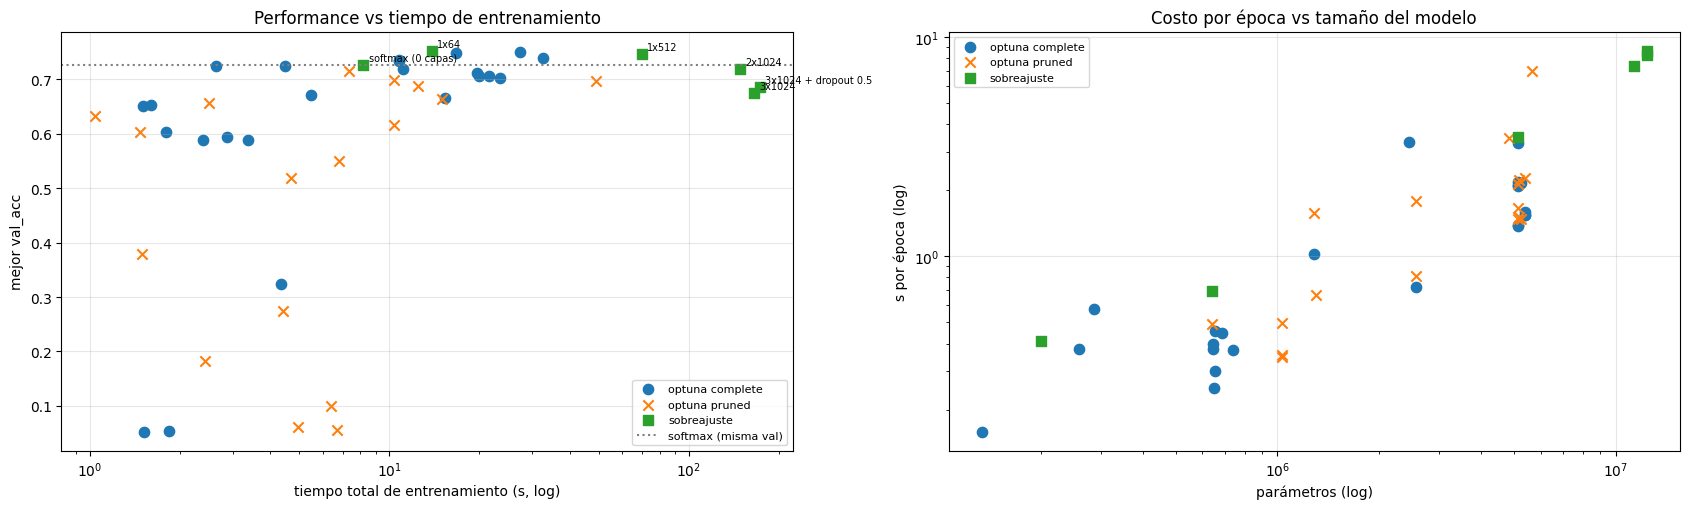

                 entrenamientos  mejor_val_acc  val_acc_media  tiempo_total_min  s_por_época_media
grupo                                                                                             
optuna complete              23          0.751          0.615             4.047              1.219
optuna pruned                17          0.715          0.476             2.456              1.747
sobreajuste                   6          0.753          0.718             9.620              4.810

Softmax (misma validación): 0.7265 | mejor MLP de la búsqueda: 0.7508 | diferencia: +0.0243
Test: MLP final 0.6950 vs softmax TP1 0.6682


In [30]:
# Comparación global de TODOS los entrenamientos: búsqueda, sobreajuste y modelo final
todos = []
for _, r in df.iterrows():
    todos.append({"grupo": "optuna " + r["estado"].lower(), "nombre": f"trial {r['trial']}",
                  "parámetros": r["n_params"], "mejor_val_acc": r["best_val_acc"],
                  "tiempo_total_s": r["train_time_s"], "s_por_época": r["s_por_época"], "épocas": r["épocas"]})
for name, r in overfit_results.items():
    h = r["history"]
    todos.append({"grupo": "sobreajuste", "nombre": name, "parámetros": r["n_params"],
                  "mejor_val_acc": max(h["val_acc"]), "tiempo_total_s": sum(h["epoch_time"]),
                  "s_por_época": np.mean(h["epoch_time"]), "épocas": len(h["val_acc"])})
df_all = pd.DataFrame(todos)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
for g, s in df_all.groupby("grupo"):
    axes[0].scatter(s["tiempo_total_s"], s["mejor_val_acc"], s=55, label=g,
                    marker={"optuna complete": "o", "optuna pruned": "x", "sobreajuste": "s"}[g])
    axes[1].scatter(s["parámetros"], s["s_por_época"], s=55, label=g,
                    marker={"optuna complete": "o", "optuna pruned": "x", "sobreajuste": "s"}[g])
for _, r in df_all[df_all["grupo"] == "sobreajuste"].iterrows():
    axes[0].annotate(r["nombre"], (r["tiempo_total_s"], r["mejor_val_acc"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
axes[0].axhline(df_all.loc[df_all["nombre"] == "softmax (0 capas)", "mejor_val_acc"].iloc[0], ls=":", c="gray",
                label="softmax (misma val)")
axes[0].set_xscale("log"); axes[0].set_xlabel("tiempo total de entrenamiento (s, log)"); axes[0].set_ylabel("mejor val_acc")
axes[0].set_title("Performance vs tiempo de entrenamiento")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("parámetros (log)")
axes[1].set_ylabel("s por época (log)"); axes[1].set_title("Costo por época vs tamaño del modelo")
for a in axes:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(df_all.groupby("grupo").agg(entrenamientos=("nombre", "count"), mejor_val_acc=("mejor_val_acc", "max"),
                                  val_acc_media=("mejor_val_acc", "mean"), tiempo_total_min=("tiempo_total_s", lambda s: s.sum() / 60),
                                  s_por_época_media=("s_por_época", "mean")).round(3).to_string())
softmax_val = df_all.loc[df_all["nombre"] == "softmax (0 capas)", "mejor_val_acc"].iloc[0]
print(f"\nSoftmax (misma validación): {softmax_val:.4f} | mejor MLP de la búsqueda: {df_ok['best_val_acc'].max():.4f} "
      f"| diferencia: {df_ok['best_val_acc'].max() - softmax_val:+.4f}")
print(f"Test: MLP final {test_accuracy:.4f} vs softmax TP1 {SOFTMAX_TP1_TEST_ACC:.4f}")

### Análisis global

| Grupo | Entrenamientos | Mejor val_acc | Media | Tiempo total |
|---|---|---|---|---|
| Optuna completos | 23 | 0.751 | 0.615 | 4,0 min |
| Optuna podados | 17 | 0.715 | 0.476 | 2,5 min |
| Experimento de sobreajuste | 6 | 0.753 | 0.718 | **9,6 min** |

**Performance.** Sobre la misma validación:
- softmax: **0.7265**;
- mejor MLP de la búsqueda: **0.7508** (+2,4 puntos);
- MLP 1×64 del experimento de sobreajuste: **0.7525** (+2,6 puntos).

En test, MLP **0.695** contra softmax **0.668** (+2,7 puntos). Las tres comparaciones coinciden: **las capas ocultas aportan ~2,5 puntos**, una mejora real pero acotada. Para clasificar temas con bolsa de palabras, la softmax ya resuelve la mayor parte del problema, porque en 10.000 dimensiones los datos son casi linealmente separables.

**Tiempo.** El gráfico de performance contra tiempo muestra que **más tiempo no compra más accuracy**:
- Los entrenamientos más largos (2×1024 y 3×1024, 2–3 minutos cada uno) están entre los **peores** en validación.
- Las mejores configuraciones (1×64, 1×512 con dropout) se entrenan en 5–30 segundos.
- **El experimento de sobreajuste, con sólo 6 entrenamientos, tardó más (9,6 min) que los 40 trials de la búsqueda (6,5 min)**: los modelos sobredimensionados son a la vez los más caros y los que peor generalizan.

**Costo por época contra tamaño.** En escala log-log, la relación es aproximadamente lineal: el costo lo domina la primera capa ($d \times h_1$). Los podados aparecen en todo el rango de tamaños: el pruner no los eligió por ser grandes, sino por rendir por debajo de la mediana.

## 10. Conclusiones

1. **Mejor configuración.** Optuna eligió un MLP de **1 capa oculta de 512 neuronas con LeakyReLU y dropout 0.5**, entrenado con **Adam** (lr = 5·10⁻⁴, β₁ = 0.95, β₂ = 0.9999) y batch 128. Usó el mismo preprocesamiento que funcionó en el TP1 (**stem, unigramas, 10.000 features**). Con stopwords da lo mismo dejarlas o sacarlas. Alcanzó 0.751 en validación y **0.695 en test**.

2. **MLP vs softmax.** Las capas ocultas mejoran **~2,5 puntos** de forma consistente: +2,4 en validación (0.751 vs 0.727) y +2,7 en test (0.695 vs 0.668). La mejora es real (supera el error estándar), pero es modesta. Su costo es ~1,7 a 20 veces más tiempo por época, según el tamaño, y la pérdida de interpretabilidad. Las confusiones principales (religión, política, computación) **no cambian**: son límites de la representación bolsa de palabras y de las propias categorías, no del modelo.

3. **Optimizadores y momentos.**
   - **Adam** dio el mejor trial y **RMSprop** fue el más robusto (mejor media). Ambos funcionan gracias a la normalización por el **momento de orden 2**, clave con features TF-IDF chicos y dispersos.
   - **SGD fracasó**: sin momento no avanza o diverge, y sólo con **momento de orden 1 alto** (0.99) llegó a 0.59, todavía sin converger.
   - En RMSprop, agregar momentum (orden 1) mejoró los resultados.
   - El análisis fANOVA confirma que **el optimizador es el hiperparámetro más importante** (0.47).
   - El **learning rate** fue más determinante que los valores de β₁/β₂. Los MLP necesitan lr ~10 veces menores que la softmax.

4. **Activaciones y profundidad.**
   - ReLU, LeakyReLU y GELU dominaron.
   - **Sigmoid fue la peor** (4 de 5 trials podados) por saturación y desvanecimiento del gradiente. Tanh quedó intermedia.
   - **Una capa oculta alcanza**: 2 capas no mejoraron y 3 capas rindieron peor y costaron más.

5. **Sobreajuste.** El modelo de **3 capas de 1024 neuronas** (12,4 M de parámetros) sobreajusta claramente: su val_loss se duplica desde su mínimo en la época 2, tiene la mayor brecha (0.31) y queda ~8 puntos por debajo del mejor modelo. El sobreajuste crece de forma **monótona con la capacidad**. El dropout lo atenuó muy poco, porque la memorización ocurre en la primera capa conectada a las palabras. El **modelo chico (1×64) fue el mejor de todo el TP** (0.7525), empatado con el de Optuna con 8 veces menos parámetros.

6. **Tiempos.**
   - La búsqueda completa (40 trials) tomó 7,3 minutos.
   - El costo por época crece con los parámetros (Spearman +0.78) y lo domina la primera capa.
   - Los 6 entrenamientos del experimento de sobreajuste tardaron **más que toda la búsqueda**: más capacidad significó más costo y peor resultado.

7. **Pruning (bonus).**
   - Podó **17 de 40 trials (42%)**, sobre todo sigmoid, SGD y lr inadecuados.
   - Ahorró ~5,0 minutos, un **43%** del tiempo de entrenamiento que habría llevado la búsqueda sin él.
   - Junto con el early stopping, ahorró más de la mitad del tiempo total (de ~14,5 a ~6,5 minutos).
   - No descartó configuraciones ganadoras: el mejor trial podado iba en 0.715, por debajo del top (0.73–0.75).

8. **Reproducibilidad.** Al re-ejecutar el notebook completo varias veces se obtuvieron **exactamente las mismas accuracies** en búsqueda, test y sobreajuste, gracias a las semillas fijas (incluida la del sampler TPE). Sólo cambian los tiempos (±10%), que dependen de la carga de la máquina; por eso las comparaciones de tiempo se hacen dentro de una misma corrida.

9. **Mejoras posibles.**
   - Incluir *weight decay* (`AdamW`) en la búsqueda.
   - Probar menos neuronas (32–128), dado que 1×64 empató con 1×512.
   - Usar validación cruzada para reducir el ruido de un único split.
   - Para atacar las confusiones semánticas, cambiar la representación: embeddings o modelos con contexto, en vez de TF-IDF.